<a href="https://colab.research.google.com/github/Hesam-Ayat/ai_course_exersize/blob/main/AH2179_Project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AH2179 Project — Early Warning of BUS Delay Service Alerts

This project uses Stockholm SL bus data from **2024** to investigate whether real-time operational data can be used to predict an upcoming BUS Delay Service Alert.

The final task is a **binary classification problem**: at each bus trip-stop observation, we predict whether the recorded `start` time of a trip-linked BUS Delay Service Alert will occur within the next **20 minutes**, using only information available up to that point.

The Service Alert `start` time is used as the prediction target. It does not tell us exactly when the underlying disruption physically began, and we do not assume that it is the exact moment when the alert was first published to passengers.

In [ ]:
# ============================================================
# SETUP AND REPRODUCIBILITY
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import glob
import gc
import time
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)

from sklearn.inspection import permutation_importance


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)


# ------------------------------------------------------------
# Project folders
# ------------------------------------------------------------

data_folder = "/content/drive/MyDrive/AH2179_Project_Data"

submission_folder = os.path.join(
    data_folder,
    "submission_outputs"
)

figures_folder = os.path.join(
    submission_folder,
    "figures"
)

modeling_folder = os.path.join(
    submission_folder,
    "modeling"
)

os.makedirs(submission_folder, exist_ok=True)
os.makedirs(figures_folder, exist_ok=True)
os.makedirs(modeling_folder, exist_ok=True)


# ------------------------------------------------------------
# Input files
# ------------------------------------------------------------

monthly_files = sorted(
    glob.glob(
        os.path.join(
            data_folder,
            "gtfs_rt_2024*.csv.gz"
        )
    )
)

alerts_file = os.path.join(
    data_folder,
    "service_alerts_2024.parquet"
)

routes_file = os.path.join(
    data_folder,
    "routes.csv"
)

trips_file = os.path.join(
    data_folder,
    "trips.csv"
)

stops_file = os.path.join(
    data_folder,
    "stops.csv"
)

transfers_file = os.path.join(
    data_folder,
    "transfers.csv"
)


print("Setup complete.")
print("Monthly GTFS-RT files:", len(monthly_files))

Mounted at /content/drive
Setup complete.
Monthly GTFS-RT files: 12


## 1. Operational GTFS-RT preprocessing

The 2024 GTFS-RT data are processed month by month in chunks because of the size of the dataset. We keep BUS observations with successful GTFS/GTFS-RT linkage and usable observed arrival-delay information. Negative and extreme delay values are retained at this stage.

In [ ]:
# ============================================================
# GTFS-RT CLEANING FUNCTION
# ============================================================

def clean_bus_chunk(chunk):
    """
    Clean one chunk of the operational GTFS-RT data.
    """

    # Keep BUS observations only
    clean = chunk[
        chunk["TransportMode"] == "BUS"
    ].copy()

    # Keep rows with successful GTFS / GTFS-RT linkage
    clean = clean[
        (clean["tripupdates_and_gtfs_not_merged_within_service_id"] == "f")
        &
        (clean["tripupdates_not_merged_with_stoptimes_or_trip"] == "f")
    ].copy()

    # Make sure arrival delay is numeric
    clean["observed_arrival_delay"] = pd.to_numeric(
        clean["observed_arrival_delay"],
        errors="coerce"
    )

    # Remove observations without usable arrival-delay information
    clean = clean.dropna(
        subset=["observed_arrival_delay"]
    )

    # Convert delay from seconds to minutes
    clean["delay_min"] = (
        clean["observed_arrival_delay"] / 60.0
    )

    # Parse service date
    clean["date_parsed"] = pd.to_datetime(
        clean["date"].astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    # Basic temporal variables
    clean["month"] = clean["date_parsed"].dt.month
    clean["weekday"] = clean["date_parsed"].dt.day_name()
    clean["dow"] = clean["date_parsed"].dt.dayofweek

    # Scheduled arrival time is stored as seconds from service-day start
    clean["hour"] = (
        clean["scheduled_arrival_time_sfm"] // 3600
    ) % 24

    return clean

In [ ]:
# ============================================================
# PROCESS FULL-YEAR GTFS-RT DATA
# ============================================================

CHUNK_SIZE = 100_000
SAMPLE_FRAC = 0.002


# ------------------------------------------------------------
# Columns needed from the monthly GTFS-RT files
# ------------------------------------------------------------

columns_needed = [
    "date",
    "LineNumber",
    "route_id",
    "TransportMode",
    "direction_id",
    "trip_id",
    "observed_stop_id",
    "scheduled_arrival_time_sfm",
    "observed_arrival_delay",
    "tripupdates_and_gtfs_not_merged_within_service_id",
    "tripupdates_not_merged_with_stoptimes_or_trip"
]


# Read identifier columns consistently as strings.
# This prevents values such as 4 and "4" from being treated
# as different identifiers across different CSV chunks.
identifier_dtypes = {
    "LineNumber": "string",
    "route_id": "string",
    "trip_id": "string",
    "observed_stop_id": "string"
}


# ------------------------------------------------------------
# Helper for exact grouped delay summaries
# ------------------------------------------------------------

def update_sum_count(sum_dict, count_dict, data, group_col):

    grouped = (
        data
        .groupby(group_col, dropna=True)["delay_min"]
        .agg(["sum", "count"])
    )

    for key, row in grouped.iterrows():

        sum_dict[key] = (
            sum_dict.get(key, 0)
            + row["sum"]
        )

        count_dict[key] = (
            count_dict.get(key, 0)
            + row["count"]
        )


# ------------------------------------------------------------
# Full-year cleaning counters
# ------------------------------------------------------------

total_raw = 0
total_bus = 0
total_valid_merge = 0
total_clean = 0

cleaning_rows = []


# ------------------------------------------------------------
# Minimal information needed for later EDA
# ------------------------------------------------------------

hour_sum = {}
hour_count = {}

weekday_sum = {}
weekday_count = {}

month_sum = {}
month_count = {}

line_sum = {}
line_count = {}

stop_sum = {}
stop_count = {}

# Small representative sample used for the delay distribution
delay_samples = []

# Keep only very large-delay observations for the later
# data-quality / extreme-value analysis
extreme_delay_rows = []


# ------------------------------------------------------------
# Process all 12 monthly files
# ------------------------------------------------------------

for file in monthly_files:

    month_number = int(
        os.path.basename(file)[12:14]
    )

    month_raw = 0
    month_bus = 0
    month_valid_merge = 0
    month_clean = 0

    reader = pd.read_csv(
        file,
        sep=";",
        compression="gzip",
        usecols=columns_needed,
        dtype=identifier_dtypes,
        chunksize=CHUNK_SIZE,
        low_memory=False
    )

    for chunk_number, chunk in enumerate(reader, start=1):

        # ====================================================
        # 1. CLEANING COUNTS
        # ====================================================

        month_raw += len(chunk)

        bus_mask = (
            chunk["TransportMode"] == "BUS"
        )

        month_bus += int(
            bus_mask.sum()
        )

        valid_merge_mask = (
            bus_mask
            &
            (
                chunk[
                    "tripupdates_and_gtfs_not_merged_within_service_id"
                ] == "f"
            )
            &
            (
                chunk[
                    "tripupdates_not_merged_with_stoptimes_or_trip"
                ] == "f"
            )
        )

        month_valid_merge += int(
            valid_merge_mask.sum()
        )


        # Apply the common cleaning function
        clean = clean_bus_chunk(chunk)

        month_clean += len(clean)


        # ====================================================
        # 2. STANDARDISE IDENTIFIERS
        # ====================================================

        # Defensive standardisation so identifiers have the same
        # representation in every chunk and can later be saved
        # safely to Parquet.

        for col in [
            "LineNumber",
            "route_id",
            "trip_id",
            "observed_stop_id"
        ]:

            clean[col] = (
                clean[col]
                .astype("string")
                .str.strip()
                .str.replace(r"\.0$", "", regex=True)
            )


        # ====================================================
        # 3. SMALL REPRESENTATIVE DELAY SAMPLE
        # ====================================================

        if len(clean) > 0:

            sample = clean["delay_min"].sample(
                frac=SAMPLE_FRAC,
                random_state=(
                    RANDOM_STATE
                    + month_number * 1000
                    + chunk_number
                )
            )

            delay_samples.extend(
                sample.tolist()
            )


        # ====================================================
        # 4. EXACT EDA SUMMARIES
        # ====================================================

        update_sum_count(
            hour_sum,
            hour_count,
            clean,
            "hour"
        )

        update_sum_count(
            weekday_sum,
            weekday_count,
            clean,
            "weekday"
        )

        update_sum_count(
            month_sum,
            month_count,
            clean,
            "month"
        )

        update_sum_count(
            line_sum,
            line_count,
            clean,
            "LineNumber"
        )

        update_sum_count(
            stop_sum,
            stop_count,
            clean,
            "observed_stop_id"
        )


        # ====================================================
        # 5. RETAIN VERY LARGE DELAY OBSERVATIONS
        # ====================================================

        extreme = clean.loc[
            clean["delay_min"] > 30,
            [
                "date",
                "LineNumber",
                "trip_id",
                "observed_stop_id",
                "delay_min"
            ]
        ].copy()

        if len(extreme) > 0:

            extreme_delay_rows.append(
                extreme
            )


        # Free memory before reading the next chunk
        del clean
        del chunk


    # ========================================================
    # MONTHLY CLEANING COUNTS
    # ========================================================

    total_raw += month_raw
    total_bus += month_bus
    total_valid_merge += month_valid_merge
    total_clean += month_clean

    cleaning_rows.append({
        "month": month_number,
        "raw_rows": month_raw,
        "bus_rows": month_bus,
        "valid_merge_rows": month_valid_merge,
        "usable_bus_rows": month_clean
    })


# ============================================================
# CLEANING SUMMARY
# ============================================================

cleaning_summary = (
    pd.DataFrame(cleaning_rows)
    .sort_values("month")
    .reset_index(drop=True)
)


full_year_cleaning = pd.DataFrame({
    "stage": [
        "Raw GTFS-RT observations",
        "BUS observations",
        "BUS observations with successful merge",
        "Usable BUS observations"
    ],
    "rows": [
        total_raw,
        total_bus,
        total_valid_merge,
        total_clean
    ]
})


# Percentage relative to the complete raw dataset
full_year_cleaning["percent_of_raw"] = (
    full_year_cleaning["rows"]
    / total_raw
    * 100
)


# Percentage relative specifically to BUS observations
full_year_cleaning["percent_of_BUS"] = [
    np.nan,
    100.0,
    total_valid_merge / total_bus * 100,
    total_clean / total_bus * 100
]


display(
    full_year_cleaning.round(2)
)


# ============================================================
# COMBINE RETAINED EXTREME OBSERVATIONS
# ============================================================

if extreme_delay_rows:

    extreme_delay_df = pd.concat(
        extreme_delay_rows,
        ignore_index=True
    )

else:

    extreme_delay_df = pd.DataFrame(
        columns=[
            "date",
            "LineNumber",
            "trip_id",
            "observed_stop_id",
            "delay_min"
        ]
    )


# Make identifier types explicit before Parquet export
for col in [
    "LineNumber",
    "trip_id",
    "observed_stop_id"
]:

    extreme_delay_df[col] = (
        extreme_delay_df[col]
        .astype("string")
    )


# ============================================================
# SAVE COMPACT PREPROCESSING OUTPUTS
# ============================================================

cleaning_summary.to_csv(
    os.path.join(
        submission_folder,
        "gtfs_rt_cleaning_summary.csv"
    ),
    index=False
)


extreme_delay_df.to_parquet(
    os.path.join(
        submission_folder,
        "extreme_delay_observations.parquet"
    ),
    index=False
)


print(
    "\nPreprocessing complete."
)

print(
    f"Delay sample size: {len(delay_samples):,}"
)

print(
    f"Extreme observations (>30 min): "
    f"{len(extreme_delay_df):,}"
)

,stage,rows,percent_of_raw,percent_of_BUS
0,Raw GTFS-RT observations,215312714,100.00,NaN
1,BUS observations,189496930,88.01,100.00
2,BUS observations with successful merge,189496930,88.01,100.00
3,Usable BUS observations,167310972,77.71,88.29



Preprocessing complete.
Delay sample size: 334,608
Extreme observations (>30 min): 197,226


## 2. Descriptive analysis of operational delay

This section gives a concise overview of the main delay patterns in the 2024 BUS data. The aim is to identify the operational and data-quality patterns that are relevant for the later modelling task, rather than to define disruption from delay magnitude alone.

,statistic,delay_min
0,Exact full-year mean,1.61
1,Sample median,1.17
2,95th percentile,6.45
3,99th percentile,12.55


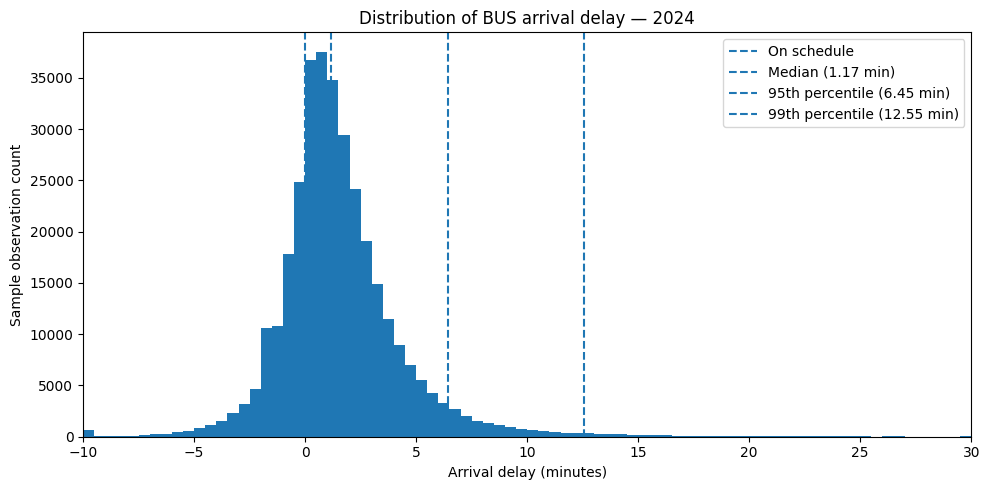

In [ ]:
# ============================================================
# FULL-YEAR DELAY DISTRIBUTION
# ============================================================

# Convert the retained representative sample to a NumPy array
all_delay_sample = np.array(
    delay_samples,
    dtype=float
)

all_delay_sample = all_delay_sample[
    np.isfinite(all_delay_sample)
]


# ------------------------------------------------------------
# Exact full-year mean
# ------------------------------------------------------------

exact_total_delay_sum = sum(
    month_sum.values()
)

exact_total_delay_count = sum(
    month_count.values()
)

exact_mean_delay = (
    exact_total_delay_sum
    / exact_total_delay_count
)


# ------------------------------------------------------------
# Sample-based distribution statistics
# ------------------------------------------------------------

median_delay = np.median(
    all_delay_sample
)

p95_delay = np.percentile(
    all_delay_sample,
    95
)

p99_delay = np.percentile(
    all_delay_sample,
    99
)


delay_statistics = pd.DataFrame({
    "statistic": [
        "Exact full-year mean",
        "Sample median",
        "95th percentile",
        "99th percentile"
    ],
    "delay_min": [
        exact_mean_delay,
        median_delay,
        p95_delay,
        p99_delay
    ]
})

display(
    delay_statistics.round(2)
)


# ------------------------------------------------------------
# Distribution plot
# ------------------------------------------------------------

plot_min = -10
plot_max = 30

bins = np.arange(
    plot_min,
    plot_max + 0.5,
    0.5
)

plt.figure(figsize=(10, 5))

plt.hist(
    all_delay_sample,
    bins=bins
)

plt.axvline(
    0,
    linestyle="--",
    label="On schedule"
)

plt.axvline(
    median_delay,
    linestyle="--",
    label=f"Median ({median_delay:.2f} min)"
)

plt.axvline(
    p95_delay,
    linestyle="--",
    label=f"95th percentile ({p95_delay:.2f} min)"
)

plt.axvline(
    p99_delay,
    linestyle="--",
    label=f"99th percentile ({p99_delay:.2f} min)"
)

plt.xlim(
    plot_min,
    plot_max
)

plt.xlabel(
    "Arrival delay (minutes)"
)

plt.ylabel(
    "Sample observation count"
)

plt.title(
    "Distribution of BUS arrival delay — 2024"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "delay_distribution_2024.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The full-year delay distribution is right-skewed. Most observations are close to schedule, while a relatively small number of large positive delays extend the upper tail. Negative values also occur because buses can arrive early. These values describe the distribution of delay but are not used as thresholds for defining disruption.

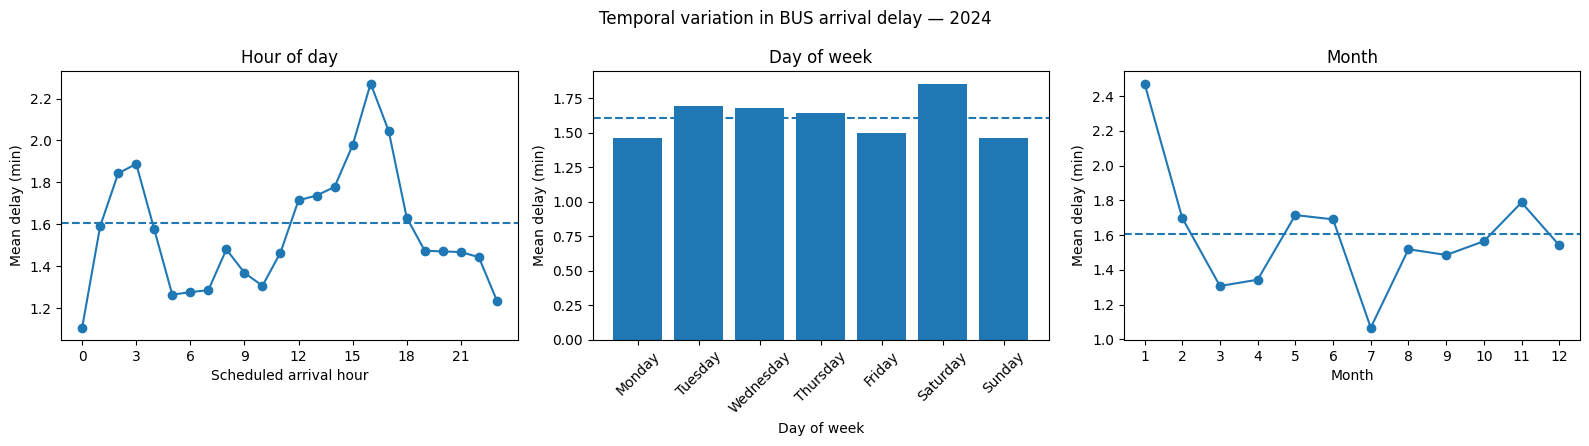

Highest hourly mean: 2.27 min at 16:00
Highest weekday mean: 1.85 min on Saturday
Highest monthly mean: 2.47 min in month 1
Lowest monthly mean: 1.07 min in month 7


In [ ]:
# ============================================================
# TEMPORAL VARIATION IN BUS DELAY
# ============================================================

def make_delay_summary(
    sum_dict,
    count_dict,
    group_name
):

    rows = []

    for key in sum_dict:

        count = count_dict[key]

        rows.append({
            group_name: key,
            "observation_count": count,
            "mean_delay_min": (
                sum_dict[key] / count
            )
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# Create temporal summary tables
# ------------------------------------------------------------

hourly_delay_df = (
    make_delay_summary(
        hour_sum,
        hour_count,
        "hour"
    )
    .sort_values("hour")
)


monthly_delay_df = (
    make_delay_summary(
        month_sum,
        month_count,
        "month"
    )
    .sort_values("month")
)


weekday_delay_df = make_delay_summary(
    weekday_sum,
    weekday_count,
    "weekday"
)


weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_delay_df["weekday"] = (
    pd.Categorical(
        weekday_delay_df["weekday"],
        categories=weekday_order,
        ordered=True
    )
)

weekday_delay_df = (
    weekday_delay_df
    .sort_values("weekday")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# One compact temporal figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4.5)
)


# Hour of day
axes[0].plot(
    hourly_delay_df["hour"],
    hourly_delay_df["mean_delay_min"],
    marker="o"
)

axes[0].axhline(
    exact_mean_delay,
    linestyle="--"
)

axes[0].set_xlabel(
    "Scheduled arrival hour"
)

axes[0].set_ylabel(
    "Mean delay (min)"
)

axes[0].set_title(
    "Hour of day"
)

axes[0].set_xticks(
    range(0, 24, 3)
)


# Day of week
axes[1].bar(
    weekday_delay_df["weekday"].astype(str),
    weekday_delay_df["mean_delay_min"]
)

axes[1].axhline(
    exact_mean_delay,
    linestyle="--"
)

axes[1].set_xlabel(
    "Day of week"
)

axes[1].set_ylabel(
    "Mean delay (min)"
)

axes[1].set_title(
    "Day of week"
)

axes[1].tick_params(
    axis="x",
    rotation=45
)


# Month
axes[2].plot(
    monthly_delay_df["month"],
    monthly_delay_df["mean_delay_min"],
    marker="o"
)

axes[2].axhline(
    exact_mean_delay,
    linestyle="--"
)

axes[2].set_xlabel(
    "Month"
)

axes[2].set_ylabel(
    "Mean delay (min)"
)

axes[2].set_title(
    "Month"
)

axes[2].set_xticks(
    range(1, 13)
)


plt.suptitle(
    "Temporal variation in BUS arrival delay — 2024"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "temporal_delay_patterns_2024.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Print the main temporal extremes
# ------------------------------------------------------------

highest_hour = hourly_delay_df.loc[
    hourly_delay_df[
        "mean_delay_min"
    ].idxmax()
]

highest_weekday = weekday_delay_df.loc[
    weekday_delay_df[
        "mean_delay_min"
    ].idxmax()
]

highest_month = monthly_delay_df.loc[
    monthly_delay_df[
        "mean_delay_min"
    ].idxmax()
]

lowest_month = monthly_delay_df.loc[
    monthly_delay_df[
        "mean_delay_min"
    ].idxmin()
]

print(
    f"Highest hourly mean: "
    f"{highest_hour['mean_delay_min']:.2f} min "
    f"at {int(highest_hour['hour']):02d}:00"
)

print(
    f"Highest weekday mean: "
    f"{highest_weekday['mean_delay_min']:.2f} min "
    f"on {highest_weekday['weekday']}"
)

print(
    f"Highest monthly mean: "
    f"{highest_month['mean_delay_min']:.2f} min "
    f"in month {int(highest_month['month'])}"
)

print(
    f"Lowest monthly mean: "
    f"{lowest_month['mean_delay_min']:.2f} min "
    f"in month {int(lowest_month['month'])}"
)

Mean delay varies systematically across time. Delay is highest in the late afternoon, varies across weekdays, and also differs considerably between months. This shows that the same delay value can occur under different operational contexts and motivates including temporal information in the later prediction model.

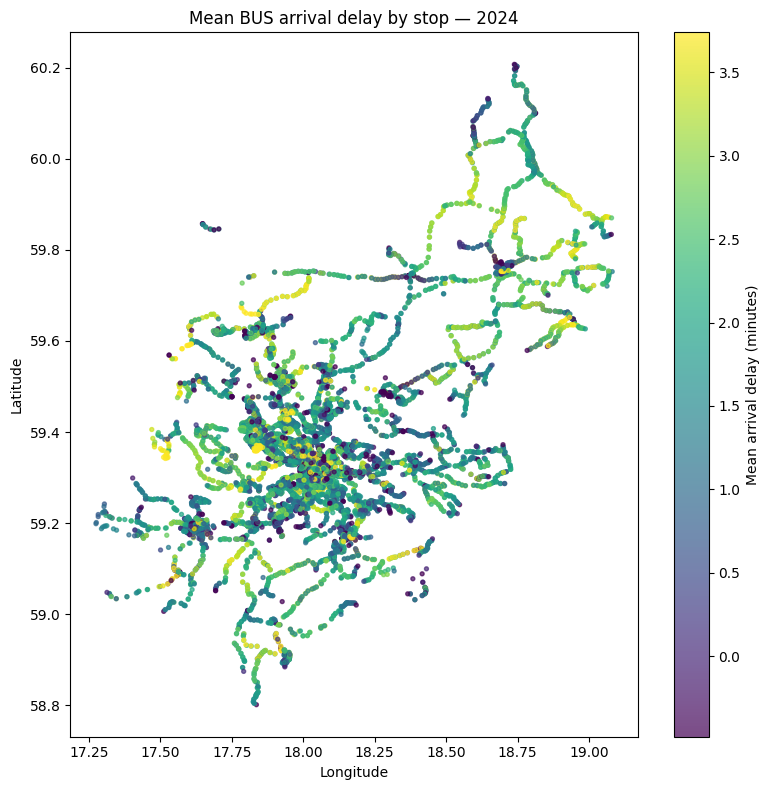

Stops shown: 10,058
Display range: -0.48 to 3.74 min


In [ ]:
# ============================================================
# SPATIAL VARIATION IN MEAN DELAY
# ============================================================

# ------------------------------------------------------------
# Create stop-level delay summary
# ------------------------------------------------------------

stop_delay_df = make_delay_summary(
    stop_sum,
    stop_count,
    "observed_stop_id"
)


# ------------------------------------------------------------
# Load static stop coordinates
# ------------------------------------------------------------

stops = pd.read_csv(
    stops_file,
    sep=";",
    dtype={
        "stop_id": "string"
    },
    low_memory=False
)


# Standardise stop identifiers
stops["stop_id"] = (
    stops["stop_id"]
    .astype("string")
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True
    )
)

stop_delay_df["observed_stop_id"] = (
    stop_delay_df["observed_stop_id"]
    .astype("string")
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True
    )
)


# ------------------------------------------------------------
# Join delay summary to static GTFS stops
# ------------------------------------------------------------

stop_map_df = stop_delay_df.merge(
    stops[
        [
            "stop_id",
            "stop_name",
            "stop_lat",
            "stop_lon"
        ]
    ],
    left_on="observed_stop_id",
    right_on="stop_id",
    how="left"
)


# ------------------------------------------------------------
# Keep stops with sufficient observations
# ------------------------------------------------------------

spatial_stops = stop_map_df[
    stop_map_df[
        "observation_count"
    ] >= 1000
].copy()

spatial_stops = spatial_stops.dropna(
    subset=[
        "stop_lat",
        "stop_lon",
        "mean_delay_min"
    ]
)


# ------------------------------------------------------------
# Robust visual colour limits only
# ------------------------------------------------------------

color_min = spatial_stops[
    "mean_delay_min"
].quantile(0.05)

color_max = spatial_stops[
    "mean_delay_min"
].quantile(0.95)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 8)
)

sc = plt.scatter(
    spatial_stops["stop_lon"],
    spatial_stops["stop_lat"],
    c=spatial_stops["mean_delay_min"],
    s=8,
    alpha=0.7,
    vmin=color_min,
    vmax=color_max
)

plt.colorbar(
    sc,
    label="Mean arrival delay (minutes)"
)

plt.xlabel(
    "Longitude"
)

plt.ylabel(
    "Latitude"
)

plt.title(
    "Mean BUS arrival delay by stop — 2024"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "spatial_mean_delay_2024.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    f"Stops shown: {len(spatial_stops):,}"
)

print(
    f"Display range: "
    f"{color_min:.2f} to "
    f"{color_max:.2f} min"
)

Mean recorded delay also varies across the bus network, with neighbouring stops in some corridors showing similar patterns. The map describes spatial variation in operation rather than confirmed disruption hotspots; high mean delay at a stop is not by itself evidence of a disruption.

In [ ]:
# ============================================================
# EXTREME-DELAY DATA-QUALITY CHECK
# ============================================================

# Summarise observations above 30 minutes by line
extreme_by_line = (
    extreme_delay_df
    .groupby("LineNumber")
    .agg(
        extreme_observations=(
            "delay_min",
            "size"
        ),
        unique_trips=(
            "trip_id",
            "nunique"
        ),
        unique_days=(
            "date",
            "nunique"
        ),
        unique_stops=(
            "observed_stop_id",
            "nunique"
        ),
        median_extreme_delay=(
            "delay_min",
            "median"
        ),
        max_delay=(
            "delay_min",
            "max"
        )
    )
    .reset_index()
    .sort_values(
        "extreme_observations",
        ascending=False
    )
)


# ------------------------------------------------------------
# Overall prevalence of >30-minute observations
# ------------------------------------------------------------

extreme_share = (
    len(extreme_delay_df)
    / total_clean
    * 100
)

print(
    f"Observations above 30 minutes: "
    f"{len(extreme_delay_df):,} "
    f"({extreme_share:.3f}% of usable BUS observations)"
)


# ------------------------------------------------------------
# Lines with most extreme observations
# ------------------------------------------------------------

print(
    "\nLines with the most observations above 30 minutes:"
)

display(
    extreme_by_line
    .head(10)
    .round(2)
)


# ------------------------------------------------------------
# Previously flagged recurring lines
# ------------------------------------------------------------

flagged_lines = [
    "908",
    "955",
    "574"
]

print(
    "\nPreviously flagged recurring extreme-delay lines:"
)

display(
    extreme_by_line[
        extreme_by_line[
            "LineNumber"
        ].isin(flagged_lines)
    ]
    .round(2)
)

Observations above 30 minutes: 197,226 (0.118% of usable BUS observations)

Lines with the most observations above 30 minutes:


,LineNumber,extreme_observations,unique_trips,unique_days,unique_stops,median_extreme_delay,max_delay
36,176,10134,248,100,85,55.60,163.25
37,177,8957,214,98,70,54.25,161.97
245,574,8345,109,318,69,44.23,112.85
83,312,8043,92,101,149,34.25,160.88
299,634,4665,40,181,88,41.95,121.98
501,952,3583,28,198,53,48.17,153.25
88,318,3359,36,37,86,36.73,69.00
297,632,3336,30,128,91,54.35,79.20
75,302,3226,43,44,41,38.47,94.77
86,316,3200,34,37,62,38.75,93.57



Previously flagged recurring extreme-delay lines:


,LineNumber,extreme_observations,unique_trips,unique_days,unique_stops,median_extreme_delay,max_delay
245,574,8345,109,318,69,44.23,112.85
495,908,2713,19,130,39,92.63,166.68
503,955,2292,25,104,20,47.05,172.52


Delays above 30 minutes are very rare overall, representing only about **0.12%** of usable BUS observations. However, these extreme values are not randomly distributed: they occur repeatedly on particular lines, trips and stops.

The full-network analysis identifies several lines with recurring extreme-delay observations. Lines **908, 955 and 574**, which were flagged during the earlier exploratory analysis, remain clear examples of this pattern, although other lines also contain large numbers of extreme observations.

Because these values may represent genuine unusual operation, systematic data behaviour, or a combination of both, they are not automatically removed and are not used to define disruption. The supervised target is instead based on documented BUS Delay Service Alerts.

## 3. Service Alert preprocessing

The Service Alert data contain repeated alert IDs because one alert can be associated with several affected routes, trips or stops. Alert IDs are used as the event-level unit and the detailed operational scope is preserved separately for later BUS linkage.

Identifiers, timestamps and alert text are cleaned before a rule-based taxonomy is applied to the unique alerts.

In [ ]:
# ============================================================
# SERVICE ALERT PREPROCESSING
# ============================================================

# Load raw Service Alert data
alerts_raw = pd.read_parquet(
    alerts_file
)

alerts = alerts_raw.copy()


# ------------------------------------------------------------
# 1. NORMALISE IDENTIFIERS
# ------------------------------------------------------------

id_columns = [
    "route_id",
    "trip_id",
    "stop_id"
]

for col in id_columns:

    alerts[col] = (
        alerts[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .replace({
            "-1": pd.NA,
            "": pd.NA,
            "None": pd.NA,
            "nan": pd.NA
        })
    )


# schedule_relationship is a coded field;
# -1 means that no value was supplied.
alerts["schedule_relationship"] = (
    pd.to_numeric(
        alerts["schedule_relationship"],
        errors="coerce"
    )
    .replace(-1, pd.NA)
    .astype("Int64")
)


# ------------------------------------------------------------
# 2. NORMALISE TIMESTAMPS
# ------------------------------------------------------------

for col in [
    "start",
    "end",
    "date_inserted"
]:

    alerts[col] = pd.to_datetime(
        alerts[col],
        errors="coerce"
    )


# 'date' is stored as YYYYMMDD
alerts["date"] = pd.to_datetime(
    alerts["date"].astype("string"),
    format="%Y%m%d",
    errors="coerce"
)


# ------------------------------------------------------------
# 3. CLEAN TEXT ENCODING
# ------------------------------------------------------------

# Keep the original text fields unchanged and create
# separate cleaned versions for analysis.

text_replacements = {
    "Ã¥": "å",
    "Ã¤": "ä",
    "Ã¶": "ö",
    "Ã…": "Å",
    "Ã„": "Ä",
    "Ã–": "Ö"
}


def clean_alert_text(series):

    cleaned = series.astype("string")

    for old, new in text_replacements.items():

        cleaned = cleaned.str.replace(
            old,
            new,
            regex=False
        )

    return cleaned.str.strip()


alerts["header_text_clean"] = clean_alert_text(
    alerts["header_text2"]
)

alerts["description_text_clean"] = clean_alert_text(
    alerts["description_text2"]
)


# ------------------------------------------------------------
# 4. ALERT-ID STRUCTURE
# ------------------------------------------------------------

alert_id_counts = (
    alerts
    .groupby("id")
    .size()
)

raw_alert_rows = len(alerts)

unique_alert_ids = alerts["id"].nunique()

repeated_alert_ids = (
    alert_id_counts > 1
).sum()


alert_structure_summary = pd.DataFrame({
    "measure": [
        "Raw Service Alert rows",
        "Unique alert IDs",
        "Alert IDs appearing more than once"
    ],
    "count": [
        raw_alert_rows,
        unique_alert_ids,
        repeated_alert_ids
    ]
})

display(
    alert_structure_summary
)


# ------------------------------------------------------------
# 5. CREATE ONE REPRESENTATIVE ROW PER ALERT ID
# ------------------------------------------------------------

# The original analysis showed that repeated rows normally
# preserve the same substantive alert content and timing.
# Their route/trip/stop scope will be reconstructed separately.

alert_level = (
    alerts
    .sort_values("date_inserted")
    .drop_duplicates(
        subset="id",
        keep="first"
    )
    .copy()
)

,measure,count
0,Raw Service Alert rows,1972779
1,Unique alert IDs,811657
2,Alert IDs appearing more than once,91456


In [ ]:
# ============================================================
# SERVICE ALERT TAXONOMY
# ============================================================

# Combine cleaned header and description text
alert_level["taxonomy_text"] = (
    alert_level[
        "header_text_clean"
    ].fillna("")
    + " | "
    + alert_level[
        "description_text_clean"
    ].fillna("")
).str.lower()


text = alert_level["taxonomy_text"]


# ------------------------------------------------------------
# Define alert themes
# ------------------------------------------------------------

is_cancellation = text.str.contains(
    r"inställd|inställt|inställda|ställ in del av tur",
    regex=True,
    na=False
)


is_stop_change = text.str.contains(
    r"indragen hållplats|indragna hållplatser|"
    r"hållplats indragen|"
    r"stannar inte vid|stannade inte vid",
    regex=True,
    na=False
)


is_boarding_restriction = text.str.contains(
    r"ingen påstigning",
    regex=True,
    na=False
)


is_delay = text.str.contains(
    r"försenad|försening",
    regex=True,
    na=False
)


is_departure_change = text.str.contains(
    r"ny avgångstid|invänta tid|återkallad",
    regex=True,
    na=False
)


is_capacity_or_formation = text.str.contains(
    r"fullsatt|långt tåg|korta tåg|kort tåg|"
    r"främre tåg|korta och långa tåg",
    regex=True,
    na=False
)


is_accessibility = text.str.contains(
    r"hiss|rulltrappa",
    regex=True,
    na=False
)


is_safety_information = text.str.contains(
    r"passerande tåg|sprängningsarbete",
    regex=True,
    na=False
)


# ------------------------------------------------------------
# Assign one primary category
# ------------------------------------------------------------

conditions = [
    is_cancellation,
    is_stop_change,
    is_boarding_restriction,
    is_delay,
    is_departure_change,
    is_capacity_or_formation,
    is_accessibility,
    is_safety_information
]


categories = [
    "Cancellation",
    "Stop unavailable / changed",
    "Boarding restriction",
    "Delay",
    "Departure-time / regulation change",
    "Capacity / vehicle formation",
    "Accessibility information",
    "Safety / operational information"
]


alert_level["alert_category"] = np.select(
    conditions,
    categories,
    default="Other / unclear"
)


# ------------------------------------------------------------
# Compact category summary
# ------------------------------------------------------------

taxonomy_summary = (
    alert_level[
        "alert_category"
    ]
    .value_counts()
    .rename_axis(
        "alert_category"
    )
    .reset_index(
        name="alert_count"
    )
)


taxonomy_summary[
    "percent_of_alerts"
] = (
    taxonomy_summary[
        "alert_count"
    ]
    / len(alert_level)
    * 100
)


display(
    taxonomy_summary.round(2)
)


# Save for later reporting
taxonomy_summary.to_csv(
    os.path.join(
        submission_folder,
        "service_alert_taxonomy.csv"
    ),
    index=False
)

,alert_category,alert_count,percent_of_alerts
0,Boarding restriction,309808,38.17
1,Safety / operational information,251573,30.99
2,Delay,174604,21.51
3,Cancellation,33734,4.16
4,Departure-time / regulation change,16090,1.98
5,Capacity / vehicle formation,13200,1.63
6,Other / unclear,7687,0.95
7,Stop unavailable / changed,3935,0.48
8,Accessibility information,1026,0.13


The Service Alert dataset contains a broad mixture of passenger and operational information rather than delay events alone. The taxonomy is therefore used to separate alert types before linking them to BUS operations.

For the later prediction task, the relevant target category is Delay. Repeated raw rows are not treated as separate events; the alert ID is used as the event-level identifier while route, trip and stop scope are preserved separately.

## 4. Service Alert timestamp semantics

Before using `start` as the temporal reference for the prediction target, we examine how it relates to `date_inserted` and `end`.

The analysis is performed at the unique-alert level. The interval `end - start` is interpreted as the recorded alert-period duration, not as the duration of the underlying physical disruption.

Insertion timing relative to recorded alert start:


,timing,alert_count,percent_of_alerts
0,First inserted before start,80,0.01
1,First inserted near start (±1 min),586037,72.20
2,First inserted after start,225540,27.79



Timestamp summary:


,measure,value
0,Alerts with usable start + first_insert,811657.00
1,Median first_insert - start (min),0.74
2,5th percentile first_insert - start (min),0.31
3,95th percentile first_insert - start (min),1.65
4,Alerts with more than one insertion time,58.00
5,Median recorded alert-period duration (min),1.98
6,Alerts with recorded period > 24 h,2811.00


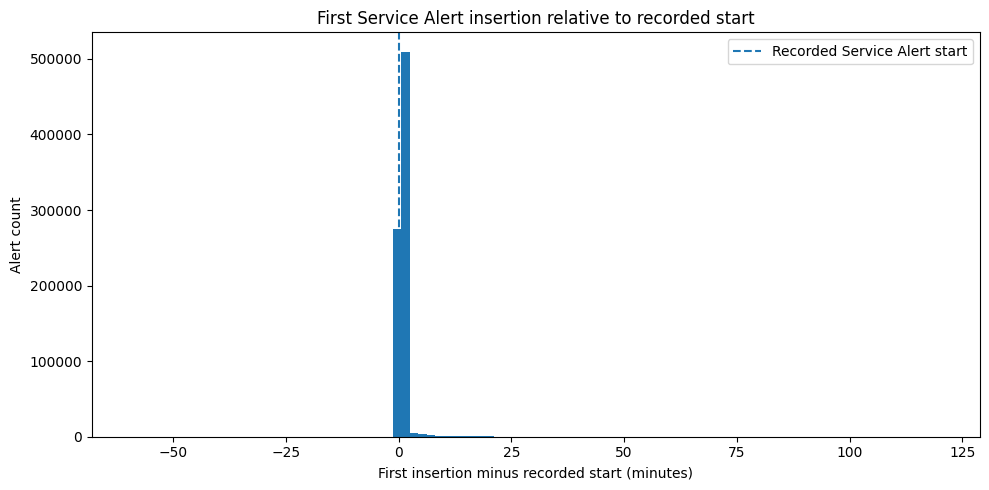

In [ ]:
# ============================================================
# SERVICE ALERT TIMESTAMP-SEMANTICS AUDIT
# ============================================================

# ------------------------------------------------------------
# 1. FIRST / LAST INSERTION TIME FOR EACH UNIQUE ALERT
# ------------------------------------------------------------

insert_stats = (
    alerts
    .groupby("id")
    .agg(
        first_insert=("date_inserted", "min"),
        last_insert=("date_inserted", "max"),
        unique_insert_times=("date_inserted", "nunique")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 2. UNIQUE-ALERT TIMESTAMP TABLE
# ------------------------------------------------------------

alert_time_audit = (
    alert_level[
        [
            "id",
            "start",
            "end"
        ]
    ]
    .merge(
        insert_stats,
        on="id",
        how="left"
    )
)


# ------------------------------------------------------------
# 3. CALCULATE TIME DIFFERENCES
# ------------------------------------------------------------

# Recorded alert-period duration
alert_time_audit["alert_period_min"] = (
    alert_time_audit["end"]
    - alert_time_audit["start"]
).dt.total_seconds() / 60


# Difference between first insertion and recorded alert start
#
# Negative = inserted before start
# Zero     = inserted at start
# Positive = inserted after start
alert_time_audit["insert_minus_start_min"] = (
    alert_time_audit["first_insert"]
    - alert_time_audit["start"]
).dt.total_seconds() / 60


# Difference between first and last insertion timestamp
alert_time_audit["insertion_span_min"] = (
    alert_time_audit["last_insert"]
    - alert_time_audit["first_insert"]
).dt.total_seconds() / 60


# ------------------------------------------------------------
# 4. DESCRIPTIVE TIMING GROUPS
# ------------------------------------------------------------

# "Near start" is defined descriptively as within ±1 minute.
NEAR_START_MIN = 1

valid_timing = alert_time_audit[
    alert_time_audit["insert_minus_start_min"].notna()
].copy()


valid_timing["insertion_timing"] = np.select(
    [
        valid_timing["insert_minus_start_min"] < -NEAR_START_MIN,

        valid_timing["insert_minus_start_min"].between(
            -NEAR_START_MIN,
            NEAR_START_MIN,
            inclusive="both"
        ),

        valid_timing["insert_minus_start_min"] > NEAR_START_MIN
    ],
    [
        "First inserted before start",
        "First inserted near start (±1 min)",
        "First inserted after start"
    ],
    default="Unknown"
)


timing_summary = (
    valid_timing["insertion_timing"]
    .value_counts()
    .reindex(
        [
            "First inserted before start",
            "First inserted near start (±1 min)",
            "First inserted after start"
        ],
        fill_value=0
    )
    .rename_axis("timing")
    .reset_index(name="alert_count")
)

timing_summary["percent_of_alerts"] = (
    timing_summary["alert_count"]
    / len(valid_timing)
    * 100
)


# ------------------------------------------------------------
# 5. COMPACT NUMERICAL SUMMARY
# ------------------------------------------------------------

timing_statistics = pd.DataFrame({
    "measure": [
        "Alerts with usable start + first_insert",
        "Median first_insert - start (min)",
        "5th percentile first_insert - start (min)",
        "95th percentile first_insert - start (min)",
        "Alerts with more than one insertion time",
        "Median recorded alert-period duration (min)",
        "Alerts with recorded period > 24 h"
    ],
    "value": [
        len(valid_timing),

        valid_timing[
            "insert_minus_start_min"
        ].median(),

        valid_timing[
            "insert_minus_start_min"
        ].quantile(0.05),

        valid_timing[
            "insert_minus_start_min"
        ].quantile(0.95),

        (
            alert_time_audit[
                "unique_insert_times"
            ] > 1
        ).sum(),

        alert_time_audit[
            "alert_period_min"
        ].median(),

        (
            alert_time_audit[
                "alert_period_min"
            ] > 24 * 60
        ).sum()
    ]
})


print("Insertion timing relative to recorded alert start:")
display(
    timing_summary.round(2)
)

print("\nTimestamp summary:")
display(
    timing_statistics.round(2)
)


# ------------------------------------------------------------
# 6. COMPACT DISTRIBUTION FIGURE
# ------------------------------------------------------------

# Limit the visible range for readability only.
# Values outside this range remain in the analysis.

plot_data = valid_timing[
    valid_timing["insert_minus_start_min"].between(
        -120,
        120
    )
]


plt.figure(figsize=(10, 5))

plt.hist(
    plot_data["insert_minus_start_min"],
    bins=96
)

plt.axvline(
    0,
    linestyle="--",
    label="Recorded Service Alert start"
)

plt.xlabel(
    "First insertion minus recorded start (minutes)"
)

plt.ylabel(
    "Alert count"
)

plt.title(
    "First Service Alert insertion relative to recorded start"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "service_alert_insert_vs_start.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. SAVE AUDIT TABLE
# ------------------------------------------------------------

alert_time_audit.to_parquet(
    os.path.join(
        submission_folder,
        "service_alert_timestamp_audit.parquet"
    ),
    index=False
)

The recorded Service Alert `start` and the first insertion timestamp are very closely aligned. The median difference is only **0.74 minutes**, and 95% of alerts are first inserted within approximately **1.65 minutes after the recorded start**. Only a negligible number of alerts are inserted before `start`.

This suggests that the recorded `start` is a reasonable temporal reference for the prediction task and is closely associated with when the alert first appears in the available dataset. However, `date_inserted` is not assumed to represent the exact time when the alert was published to passengers.

The interval `end - start` is interpreted only as the **recorded alert-period duration**, not as the physical duration of the underlying delay or disruption.

## 5. Service Alert event reconstruction and BUS linkage

Each unique alert ID is treated as one alert event, while its associated route, trip and stop records are retained separately as the event scope.

The reconstructed events are linked to static GTFS data to identify BUS-related alerts. Route- or trip-level matches are treated as strong BUS evidence, while stop-only matches are kept separate because stops can potentially be shared across transport modes.

For the prediction task, only strongly BUS-linked **Delay** alerts with reliable trip-level scope and suitable recorded alert periods are retained.

In [ ]:
# ============================================================
# RECONSTRUCT SERVICE ALERT EVENTS
# ============================================================

# ------------------------------------------------------------
# 1. Preserve route / trip / stop scope separately
# ------------------------------------------------------------

event_scope = (
    alerts[
        [
            "id",
            "route_id",
            "trip_id",
            "stop_id"
        ]
    ]
    .drop_duplicates()
    .copy()
)


# ------------------------------------------------------------
# 2. Summarise scope at alert-event level
# ------------------------------------------------------------

scope_stats = (
    event_scope
    .groupby("id")
    .agg(
        scope_rows=("id", "size"),
        affected_routes=("route_id", "nunique"),
        affected_trips=("trip_id", "nunique"),
        affected_stops=("stop_id", "nunique")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 3. Create one row per unique alert ID
# ------------------------------------------------------------

candidate_events = (
    alert_level[
        [
            "id",
            "start",
            "end",
            "cause",
            "header_text_clean",
            "description_text_clean",
            "alert_category"
        ]
    ]
    .copy()
)


# Add insertion information from the timestamp audit
candidate_events = candidate_events.merge(
    insert_stats,
    on="id",
    how="left"
)


# Add event-scope counts
candidate_events = candidate_events.merge(
    scope_stats,
    on="id",
    how="left"
)


# ------------------------------------------------------------
# 4. Recorded alert-period duration
# ------------------------------------------------------------

candidate_events["alert_period_min"] = (
    candidate_events["end"]
    - candidate_events["start"]
).dt.total_seconds() / 60

candidate_events["alert_period_hours"] = (
    candidate_events["alert_period_min"] / 60
)

candidate_events["alert_period_days"] = (
    candidate_events["alert_period_hours"] / 24
)


# ------------------------------------------------------------
# 5. Data-quality flags
# ------------------------------------------------------------

placeholder_end = pd.Timestamp(
    "2038-01-18 03:14:00"
)

candidate_events["placeholder_end_2038"] = (
    candidate_events["end"]
    == placeholder_end
)

candidate_events["longer_than_24h"] = (
    candidate_events["alert_period_hours"] > 24
)

candidate_events["longer_than_7d"] = (
    candidate_events["alert_period_days"] > 7
)


# Sort chronologically
candidate_events = (
    candidate_events
    .sort_values(
        ["start", "id"]
    )
    .reset_index(drop=True)
)


print(
    "Reconstructed alert events:",
    f"{len(candidate_events):,}"
)

print(
    "Preserved event-scope rows:",
    f"{len(event_scope):,}"
)

Reconstructed alert events: 811,657
Preserved event-scope rows: 1,972,779


In [ ]:
# ============================================================
# LINK SERVICE ALERT EVENTS TO BUS OPERATIONS
# ============================================================

# ------------------------------------------------------------
# 1. Load static GTFS route and trip tables
# ------------------------------------------------------------

routes_static = pd.read_csv(
    routes_file,
    sep=";",
    low_memory=False
)

trips_static = pd.read_csv(
    trips_file,
    sep=";",
    low_memory=False
)


# ------------------------------------------------------------
# 2. Normalise identifiers
# ------------------------------------------------------------

def normalize_id(series):

    return (
        series
        .astype("string")
        .str.strip()
        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
        .replace({
            "-1": pd.NA,
            "": pd.NA,
            "None": pd.NA,
            "nan": pd.NA
        })
    )


routes_static["route_id"] = normalize_id(
    routes_static["route_id"]
)

trips_static["route_id"] = normalize_id(
    trips_static["route_id"]
)

trips_static["trip_id"] = normalize_id(
    trips_static["trip_id"]
)


# ------------------------------------------------------------
# 3. Identify BUS routes and BUS trips
# ------------------------------------------------------------

routes_static["route_type"] = pd.to_numeric(
    routes_static["route_type"],
    errors="coerce"
)


# Standard GTFS bus = 3.
# Extended GTFS bus categories can use 700–799.
bus_routes = routes_static[
    (routes_static["route_type"] == 3)
    |
    (
        (routes_static["route_type"] >= 700)
        &
        (routes_static["route_type"] < 800)
    )
].copy()


bus_route_ids = set(
    bus_routes["route_id"].dropna()
)


bus_trips = trips_static[
    trips_static["route_id"].isin(
        bus_route_ids
    )
].copy()


bus_trip_ids = set(
    bus_trips["trip_id"].dropna()
)


# Stops actually observed in the cleaned BUS operational data
bus_stop_ids = set(
    pd.Series(
        list(stop_sum.keys()),
        dtype="string"
    )
    .str.strip()
    .dropna()
)


# ------------------------------------------------------------
# 4. Match each scope record to BUS
# ------------------------------------------------------------

event_scope_bus = event_scope.copy()


event_scope_bus["bus_route_match"] = (
    event_scope_bus["route_id"]
    .isin(bus_route_ids)
)

event_scope_bus["bus_trip_match"] = (
    event_scope_bus["trip_id"]
    .isin(bus_trip_ids)
)

event_scope_bus["bus_stop_match"] = (
    event_scope_bus["stop_id"]
    .isin(bus_stop_ids)
)


# ------------------------------------------------------------
# 5. Aggregate BUS evidence to alert-event level
# ------------------------------------------------------------

bus_linkage = (
    event_scope_bus
    .groupby("id")
    .agg(
        bus_route_match=(
            "bus_route_match",
            "max"
        ),
        bus_trip_match=(
            "bus_trip_match",
            "max"
        ),
        bus_stop_match=(
            "bus_stop_match",
            "max"
        )
    )
    .reset_index()
)


# Strong BUS evidence requires route or trip linkage.
# Stop-only linkage is retained separately.
bus_linkage["bus_link_type"] = np.select(
    [
        (
            bus_linkage["bus_route_match"]
            |
            bus_linkage["bus_trip_match"]
        ),
        (
            ~bus_linkage["bus_route_match"]
            &
            ~bus_linkage["bus_trip_match"]
            &
            bus_linkage["bus_stop_match"]
        )
    ],
    [
        "Strong BUS link",
        "Possible BUS link — stop only"
    ],
    default="No BUS link"
)


candidate_events = candidate_events.merge(
    bus_linkage,
    on="id",
    how="left"
)


# ------------------------------------------------------------
# 6. Main BUS subset
# ------------------------------------------------------------

strong_bus_events = candidate_events[
    candidate_events["bus_link_type"]
    == "Strong BUS link"
].copy()

In [ ]:
# ============================================================
# PREPARE TRIP-LINKED BUS DELAY EVENTS
# ============================================================

# ------------------------------------------------------------
# 1. Strongly BUS-linked Delay alerts
# ------------------------------------------------------------

strong_bus_delay_events = strong_bus_events[
    strong_bus_events["alert_category"]
    == "Delay"
].copy()


# ------------------------------------------------------------
# 2. Require reliable BUS trip linkage
# ------------------------------------------------------------

trip_linked_delay_events = (
    strong_bus_delay_events[
        strong_bus_delay_events[
            "bus_trip_match"
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# 3. Exclude unsuitable recorded alert periods
# ------------------------------------------------------------

# These alerts remain in the reconstructed event archive,
# but do not generate clean primary modelling labels.

usable_delay_events = (
    trip_linked_delay_events[
        ~trip_linked_delay_events[
            "longer_than_24h"
        ]
        &
        ~trip_linked_delay_events[
            "placeholder_end_2038"
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# 4. Recover original trip / stop scope
# ------------------------------------------------------------

usable_delay_ids = set(
    usable_delay_events["id"]
)


delay_scope = event_scope_bus[
    event_scope_bus["id"].isin(
        usable_delay_ids
    )
    &
    event_scope_bus["bus_trip_match"]
].copy()


delay_scope = delay_scope.merge(
    usable_delay_events[
        [
            "id",
            "start",
            "end"
        ]
    ],
    on="id",
    how="left"
)


# ------------------------------------------------------------
# 5. Resolve mixed trip / stop scope
# ------------------------------------------------------------

# Some event-trip combinations contain both:
# - one or more specific stops
# - a row without a stop
#
# If specific stops are given, they take priority.

event_trip_scope_check = (
    delay_scope
    .groupby(
        [
            "id",
            "trip_id"
        ]
    )
    .agg(
        stop_specific_rows=(
            "stop_id",
            lambda x: x.notna().sum()
        ),
        missing_stop_rows=(
            "stop_id",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)


trip_has_specific_stops = set(
    map(
        tuple,
        event_trip_scope_check[
            event_trip_scope_check[
                "stop_specific_rows"
            ] > 0
        ][
            [
                "id",
                "trip_id"
            ]
        ].to_numpy()
    )
)


# Stop-specific event scope
delay_stop_events_final = (
    delay_scope[
        delay_scope["stop_id"].notna()
    ][
        [
            "id",
            "trip_id",
            "stop_id",
            "start",
            "end"
        ]
    ]
    .drop_duplicates()
)


# Genuine trip-wide event scope
delay_trip_events_final = (
    delay_scope[
        delay_scope["stop_id"].isna()
    ][
        [
            "id",
            "trip_id",
            "start",
            "end"
        ]
    ]
    .drop_duplicates()
)


delay_trip_events_final = (
    delay_trip_events_final[
        ~delay_trip_events_final[
            [
                "id",
                "trip_id"
            ]
        ]
        .apply(
            tuple,
            axis=1
        )
        .isin(
            trip_has_specific_stops
        )
    ]
)


# ============================================================
# COMPACT EVENT FUNNEL
# ============================================================

event_funnel = pd.DataFrame({
    "stage": [
        "Unique Service Alert events",
        "Strongly BUS-linked events",
        "Strongly BUS-linked Delay events",
        "Trip-linked BUS Delay events",
        "Usable trip-linked BUS Delay events"
    ],
    "event_count": [
        len(candidate_events),
        len(strong_bus_events),
        len(strong_bus_delay_events),
        len(trip_linked_delay_events),
        len(usable_delay_events)
    ]
})


display(
    event_funnel
)


print(
    "\nFinal stop-specific scope rows:",
    f"{len(delay_stop_events_final):,}"
)

print(
    "Final genuinely trip-wide scope rows:",
    f"{len(delay_trip_events_final):,}"
)


# ------------------------------------------------------------
# Save modelling-relevant alert tables
# ------------------------------------------------------------

delay_stop_events_final.to_parquet(
    os.path.join(
        submission_folder,
        "delay_stop_events_final.parquet"
    ),
    index=False
)

delay_trip_events_final.to_parquet(
    os.path.join(
        submission_folder,
        "delay_trip_events_final.parquet"
    ),
    index=False
)

,stage,event_count
0,Unique Service Alert events,811657
1,Strongly BUS-linked events,174104
2,Strongly BUS-linked Delay events,152398
3,Trip-linked BUS Delay events,152182
4,Usable trip-linked BUS Delay events,152127



Final stop-specific scope rows: 699,288
Final genuinely trip-wide scope rows: 106,078


The reconstruction reduces the raw Service Alert feed to one event per alert ID while preserving the affected operational scope separately.

Of the 811,657 unique alerts, 174,104 have strong BUS linkage through a route or trip identifier. Delay alerts dominate this BUS-linked subset. For the final trip-level analysis, only Delay alerts with reliable BUS trip linkage and suitable recorded alert periods are retained.

Stop-only BUS matches are not used for the primary target because they provide weaker transport-mode evidence. Alerts with very long or placeholder-ended recorded periods remain in the event archive but are excluded from clean modelling labels.

## 6. Operational delay relative to recorded Service Alert timing

We next examine how observed BUS delay relates to matching Delay Service Alerts.

For this analysis, the time of each operational observation is approximated as the **scheduled arrival time plus the observed arrival delay**. This represents when the observed delay is realised, rather than using the scheduled time alone.

Two comparisons are made:

1. arrival delay during a matching recorded Delay-alert period versus observations in the same relevant scope when no matching Delay alert is active;
2. arrival delay before and after the recorded Service Alert `start`.

The analysis is descriptive and does not assume that the Service Alert causes the observed delay.

In [ ]:
# ============================================================
# PREPARE ALERT LOOKUPS
# ============================================================

WINDOW_BEFORE_MIN = 60
WINDOW_AFTER_MIN = 120
BIN_WIDTH_MIN = 10

window_before_ns = (
    WINDOW_BEFORE_MIN
    * 60
    * 1_000_000_000
)

window_after_ns = (
    WINDOW_AFTER_MIN
    * 60
    * 1_000_000_000
)


# ------------------------------------------------------------
# Standardise final alert-scope tables
# ------------------------------------------------------------

delay_stop_events_final = (
    delay_stop_events_final.copy()
)

delay_trip_events_final = (
    delay_trip_events_final.copy()
)

for col in ["trip_id", "stop_id"]:

    if col in delay_stop_events_final.columns:

        delay_stop_events_final[col] = normalize_id(
            delay_stop_events_final[col]
        )

delay_trip_events_final["trip_id"] = normalize_id(
    delay_trip_events_final["trip_id"]
)


for table in [
    delay_stop_events_final,
    delay_trip_events_final
]:

    table["start"] = pd.to_datetime(
        table["start"],
        errors="coerce"
    )

    table["end"] = pd.to_datetime(
        table["end"],
        errors="coerce"
    )


# Trip-stop key for stop-specific alerts
delay_stop_events_final["trip_stop_key"] = (
    delay_stop_events_final["trip_id"]
    + "|"
    + delay_stop_events_final["stop_id"]
)


# ------------------------------------------------------------
# Helper 1: active alert-period lookup
# ------------------------------------------------------------

def build_interval_lookup(data, key_column):

    lookup = {}

    for key, group in data.groupby(
        key_column,
        sort=False
    ):

        group = group[
            group["start"].notna()
            & group["end"].notna()
        ]

        if len(group) == 0:
            continue

        starts = (
            group["start"]
            .astype("int64")
            .to_numpy()
        )

        ends = (
            group["end"]
            .astype("int64")
            .to_numpy()
        )

        order = np.argsort(starts)

        starts = starts[order]
        ends = ends[order]

        lookup[key] = (
            starts,
            np.maximum.accumulate(ends)
        )

    return lookup


# ------------------------------------------------------------
# Helper 2: recorded-start lookup
# ------------------------------------------------------------

def build_start_lookup(data, key_column):

    lookup = {}

    for key, group in data.groupby(
        key_column,
        sort=False
    ):

        group = group[
            group["start"].notna()
        ]

        if len(group) == 0:
            continue

        starts = (
            group["start"]
            .astype("int64")
            .to_numpy()
        )

        event_ids = (
            group["id"]
            .astype("int64")
            .to_numpy()
        )

        order = np.argsort(starts)

        lookup[key] = (
            starts[order],
            event_ids[order]
        )

    return lookup


# ------------------------------------------------------------
# Helper 3: test whether matching alert is active
# ------------------------------------------------------------

def mark_active_alerts(
    data,
    key_column,
    lookup
):

    active = np.zeros(
        len(data),
        dtype=bool
    )

    if len(data) == 0:
        return active

    times = (
        data["obs_ts"]
        .astype("int64")
        .to_numpy()
    )

    grouped_positions = (
        data
        .groupby(
            key_column,
            sort=False
        )
        .indices
    )

    for key, positions in grouped_positions.items():

        if key not in lookup:
            continue

        starts, cumulative_ends = lookup[key]

        group_times = times[positions]

        interval_index = (
            np.searchsorted(
                starts,
                group_times,
                side="right"
            )
            - 1
        )

        valid = (
            interval_index >= 0
        )

        group_active = np.zeros(
            len(positions),
            dtype=bool
        )

        group_active[valid] = (
            cumulative_ends[
                interval_index[valid]
            ]
            >= group_times[valid]
        )

        active[positions] = group_active

    return active


# ------------------------------------------------------------
# Helper 4: find nearest matching recorded alert start
# ------------------------------------------------------------

def match_nearest_start(
    data,
    key_column,
    lookup
):

    matched_event = np.full(
        len(data),
        -1,
        dtype=np.int64
    )

    relative_min = np.full(
        len(data),
        np.nan
    )

    if len(data) == 0:
        return matched_event, relative_min

    times = (
        data["obs_ts"]
        .astype("int64")
        .to_numpy()
    )

    grouped_positions = (
        data
        .groupby(
            key_column,
            sort=False
        )
        .indices
    )

    for key, positions in grouped_positions.items():

        if key not in lookup:
            continue

        starts, event_ids = lookup[key]

        group_times = times[positions]

        # First recorded start at or after each observation
        next_index = np.searchsorted(
            starts,
            group_times,
            side="left"
        )

        best_abs = np.full(
            len(positions),
            np.inf
        )

        best_rel = np.full(
            len(positions),
            np.nan
        )

        best_event = np.full(
            len(positions),
            -1,
            dtype=np.int64
        )


        # ----------------------------------------
        # Previous recorded start
        # ----------------------------------------

        previous_index = (
            next_index - 1
        )

        valid_previous = (
            previous_index >= 0
        )

        if valid_previous.any():

            rel_ns = (
                group_times[
                    valid_previous
                ]
                -
                starts[
                    previous_index[
                        valid_previous
                    ]
                ]
            )

            valid_window = (
                (rel_ns >= -window_before_ns)
                &
                (rel_ns < window_after_ns)
            )

            positions_previous = (
                np.where(
                    valid_previous
                )[0][
                    valid_window
                ]
            )

            rel_valid = (
                rel_ns[
                    valid_window
                ]
            )

            best_abs[
                positions_previous
            ] = np.abs(
                rel_valid
            )

            best_rel[
                positions_previous
            ] = (
                rel_valid
                / 60
                / 1_000_000_000
            )

            best_event[
                positions_previous
            ] = (
                event_ids[
                    previous_index[
                        valid_previous
                    ][
                        valid_window
                    ]
                ]
            )


        # ----------------------------------------
        # Next recorded start
        # ----------------------------------------

        valid_next = (
            next_index < len(starts)
        )

        if valid_next.any():

            rel_ns = (
                group_times[
                    valid_next
                ]
                -
                starts[
                    next_index[
                        valid_next
                    ]
                ]
            )

            valid_window = (
                (rel_ns >= -window_before_ns)
                &
                (rel_ns < window_after_ns)
            )

            candidate_positions = (
                np.where(
                    valid_next
                )[0][
                    valid_window
                ]
            )

            rel_valid = (
                rel_ns[
                    valid_window
                ]
            )

            candidate_abs = np.abs(
                rel_valid
            )

            better = (
                candidate_abs
                <
                best_abs[
                    candidate_positions
                ]
            )

            target_positions = (
                candidate_positions[
                    better
                ]
            )

            best_abs[
                target_positions
            ] = candidate_abs[
                better
            ]

            best_rel[
                target_positions
            ] = (
                rel_valid[
                    better
                ]
                / 60
                / 1_000_000_000
            )

            best_event[
                target_positions
            ] = (
                event_ids[
                    next_index[
                        valid_next
                    ][
                        valid_window
                    ][
                        better
                    ]
                ]
            )


        matched_event[
            positions
        ] = best_event

        relative_min[
            positions
        ] = best_rel

    return matched_event, relative_min


# ------------------------------------------------------------
# Build lookup objects
# ------------------------------------------------------------

trip_interval_lookup = build_interval_lookup(
    delay_trip_events_final,
    "trip_id"
)

stop_interval_lookup = build_interval_lookup(
    delay_stop_events_final,
    "trip_stop_key"
)

trip_start_lookup = build_start_lookup(
    delay_trip_events_final,
    "trip_id"
)

stop_start_lookup = build_start_lookup(
    delay_stop_events_final,
    "trip_stop_key"
)


# Relevant operational scope
tripwide_trip_ids = set(
    delay_trip_events_final[
        "trip_id"
    ].dropna()
)

stop_specific_keys = set(
    delay_stop_events_final[
        "trip_stop_key"
    ].dropna()
)

stop_specific_trip_ids = set(
    delay_stop_events_final[
        "trip_id"
    ].dropna()
)

relevant_trip_ids = (
    tripwide_trip_ids
    |
    stop_specific_trip_ids
)


print(
    "Trip-wide alert keys:",
    f"{len(trip_interval_lookup):,}"
)

print(
    "Stop-specific alert keys:",
    f"{len(stop_interval_lookup):,}"
)

print(
    "Relevant BUS trip IDs:",
    f"{len(relevant_trip_ids):,}"
)

Trip-wide alert keys: 31,482
Stop-specific alert keys: 171,605
Relevant BUS trip IDs: 36,234


In [ ]:
# ============================================================
# CORRECTED FULL-YEAR ALERT / DELAY ANALYSIS
# ============================================================

# ------------------------------------------------------------
# A. Active-alert comparison summaries
# ------------------------------------------------------------

comparison_totals = {
    "Matching Delay alert active": {
        "count": 0,
        "sum_delay": 0.0
    },
    "No matching Delay alert active": {
        "count": 0,
        "sum_delay": 0.0
    }
}

SAMPLE_FRAC_COMPARE = 0.01

rng_compare = np.random.default_rng(
    RANDOM_STATE
)

comparison_samples = {
    "Matching Delay alert active": [],
    "No matching Delay alert active": []
}


# ------------------------------------------------------------
# B. Event-centred summaries
# ------------------------------------------------------------

bin_starts = np.arange(
    -WINDOW_BEFORE_MIN,
    WINDOW_AFTER_MIN,
    BIN_WIDTH_MIN
)

bin_summary = {
    int(bin_start): {
        "count": 0,
        "sum_delay": 0.0
    }
    for bin_start in bin_starts
}

SAMPLE_FRAC_EVENT = 0.01

rng_event = np.random.default_rng(
    RANDOM_STATE + 1
)

bin_samples = {
    int(bin_start): []
    for bin_start in bin_starts
}

matched_event_ids = set()

total_event_centered_observations = 0
total_relevant_observations = 0


# ------------------------------------------------------------
# C. Scan all monthly GTFS-RT files once
# ------------------------------------------------------------

for file in monthly_files:

    reader = pd.read_csv(
        file,
        sep=";",
        compression="gzip",
        usecols=columns_needed,
        dtype=identifier_dtypes,
        chunksize=CHUNK_SIZE,
        low_memory=False
    )

    for chunk in reader:

        # Same operational cleaning rules used earlier
        chunk = clean_bus_chunk(
            chunk
        )

        if len(chunk) == 0:
            continue


        # ----------------------------------------
        # Restrict to trips relevant to BUS Delay alerts
        # ----------------------------------------

        chunk = chunk[
            chunk["trip_id"].isin(
                relevant_trip_ids
            )
        ].copy()

        if len(chunk) == 0:
            continue


        # ----------------------------------------
        # Construct observation timestamp
        #
        # observation time =
        # scheduled arrival + observed arrival delay
        # ----------------------------------------

        scheduled_seconds = pd.to_numeric(
            chunk[
                "scheduled_arrival_time_sfm"
            ],
            errors="coerce"
        )

        chunk["scheduled_ts"] = (
            chunk["date_parsed"]
            +
            pd.to_timedelta(
                scheduled_seconds,
                unit="s"
            )
        )

        chunk["obs_ts"] = (
            chunk["scheduled_ts"]
            +
            pd.to_timedelta(
                chunk["observed_arrival_delay"],
                unit="s"
            )
        )


        chunk = chunk[
            chunk["obs_ts"].notna()
        ].copy()

        if len(chunk) == 0:
            continue


        # ----------------------------------------
        # Trip-stop key
        # ----------------------------------------

        chunk["stop_id"] = (
            chunk["observed_stop_id"]
        )

        chunk["trip_stop_key"] = (
            chunk["trip_id"]
            + "|"
            + chunk["stop_id"]
        )


        # ----------------------------------------
        # Keep only operational scope relevant
        # to the reconstructed alerts
        # ----------------------------------------

        eligible_tripwide = (
            chunk["trip_id"]
            .isin(
                tripwide_trip_ids
            )
        )

        eligible_stop_specific = (
            chunk["trip_stop_key"]
            .isin(
                stop_specific_keys
            )
        )

        chunk = chunk[
            eligible_tripwide
            |
            eligible_stop_specific
        ].copy()

        if len(chunk) == 0:
            continue


        total_relevant_observations += (
            len(chunk)
        )


        # ====================================================
        # ANALYSIS A:
        # MATCHING ALERT PERIOD ACTIVE VS NOT ACTIVE
        # ====================================================

        active_trip = mark_active_alerts(
            chunk,
            "trip_id",
            trip_interval_lookup
        )

        active_stop = mark_active_alerts(
            chunk,
            "trip_stop_key",
            stop_interval_lookup
        )

        chunk["alert_active"] = (
            active_trip
            |
            active_stop
        )


        for active_value, label in [
            (
                True,
                "Matching Delay alert active"
            ),
            (
                False,
                "No matching Delay alert active"
            )
        ]:

            subset = chunk[
                chunk["alert_active"]
                == active_value
            ]

            if len(subset) == 0:
                continue

            comparison_totals[
                label
            ]["count"] += len(
                subset
            )

            comparison_totals[
                label
            ]["sum_delay"] += (
                subset[
                    "delay_min"
                ].sum()
            )


            # Representative sample for median / percentiles
            sample_mask = (
                rng_compare.random(
                    len(subset)
                )
                <
                SAMPLE_FRAC_COMPARE
            )

            values = (
                subset.loc[
                    sample_mask,
                    "delay_min"
                ]
                .to_numpy()
            )

            if len(values) > 0:

                comparison_samples[
                    label
                ].append(
                    values
                )


        # ====================================================
        # ANALYSIS B:
        # DELAY RELATIVE TO RECORDED SERVICE ALERT START
        # ====================================================

        (
            trip_event_id,
            trip_relative_min
        ) = match_nearest_start(
            chunk,
            "trip_id",
            trip_start_lookup
        )


        (
            stop_event_id,
            stop_relative_min
        ) = match_nearest_start(
            chunk,
            "trip_stop_key",
            stop_start_lookup
        )


        # Use whichever valid matching recorded start
        # is temporally closer.
        trip_valid = (
            trip_event_id != -1
        )

        stop_valid = (
            stop_event_id != -1
        )

        choose_stop = (
            stop_valid
            &
            (
                ~trip_valid
                |
                (
                    np.abs(
                        stop_relative_min
                    )
                    <
                    np.abs(
                        trip_relative_min
                    )
                )
            )
        )


        final_event_id = (
            trip_event_id.copy()
        )

        final_relative_min = (
            trip_relative_min.copy()
        )


        final_event_id[
            choose_stop
        ] = (
            stop_event_id[
                choose_stop
            ]
        )

        final_relative_min[
            choose_stop
        ] = (
            stop_relative_min[
                choose_stop
            ]
        )


        matched = (
            final_event_id != -1
        )

        if not matched.any():
            continue


        matched_chunk = (
            chunk.loc[
                matched,
                [
                    "delay_min"
                ]
            ]
            .copy()
        )

        matched_chunk[
            "event_id"
        ] = (
            final_event_id[
                matched
            ]
        )

        matched_chunk[
            "relative_min"
        ] = (
            final_relative_min[
                matched
            ]
        )


        # 10-minute relative-time bin
        matched_chunk[
            "bin_start_min"
        ] = (
            np.floor(
                matched_chunk[
                    "relative_min"
                ]
                / BIN_WIDTH_MIN
            )
            * BIN_WIDTH_MIN
        ).astype(int)


        matched_chunk = matched_chunk[
            matched_chunk[
                "bin_start_min"
            ].isin(
                bin_summary.keys()
            )
        ]


        if len(matched_chunk) == 0:
            continue


        total_event_centered_observations += (
            len(matched_chunk)
        )


        matched_event_ids.update(
            matched_chunk[
                "event_id"
            ].unique()
        )


        # Exact sums and counts
        grouped_bins = (
            matched_chunk
            .groupby(
                "bin_start_min"
            )[
                "delay_min"
            ]
            .agg(
                ["count", "sum"]
            )
        )


        for bin_value, row in (
            grouped_bins.iterrows()
        ):

            bin_value = int(
                bin_value
            )

            bin_summary[
                bin_value
            ]["count"] += int(
                row["count"]
            )

            bin_summary[
                bin_value
            ]["sum_delay"] += float(
                row["sum"]
            )


        # Representative sample for medians
        sample_mask = (
            rng_event.random(
                len(matched_chunk)
            )
            <
            SAMPLE_FRAC_EVENT
        )

        sampled = matched_chunk.loc[
            sample_mask,
            [
                "bin_start_min",
                "delay_min"
            ]
        ]


        for bin_value, group in (
            sampled.groupby(
                "bin_start_min"
            )
        ):

            bin_samples[
                int(bin_value)
            ].append(
                group[
                    "delay_min"
                ].to_numpy()
            )


print("Full-year corrected scan complete.")
print(
    "Relevant operational observations:",
    f"{total_relevant_observations:,}"
)

Full-year corrected scan complete.
Relevant operational observations: 70,481,650


,comparison_group,observation_count,mean_delay_min,sample_count,sample_median_delay_min,sample_p95_delay_min
0,Matching Delay alert active,2352108,7.27,23548,6.43,16.98
1,No matching Delay alert active,68129542,1.70,681272,1.25,6.43



Difference in mean delay: 5.57 min


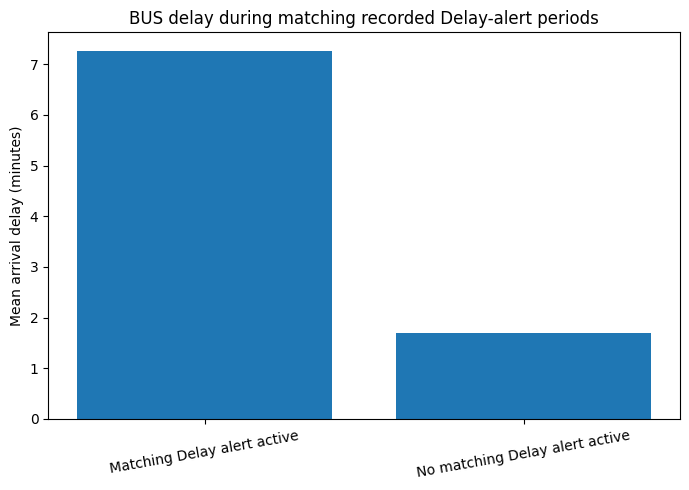

,bin_start_min,bin_end_min,bin_mid_min,observation_count,mean_delay_min,sample_count,sample_median_delay_min
0,-60,-50,-55.0,21520,1.44,207,0.93
1,-50,-40,-45.0,40925,1.57,418,1.09
2,-40,-30,-35.0,74908,1.85,801,1.58
3,-30,-20,-25.0,133545,2.30,1330,1.90
4,-20,-10,-15.0,213562,3.17,2147,2.53
5,-10,0,-5.0,364856,5.62,3686,4.95
6,0,10,5.0,729032,7.23,7263,6.65
7,10,20,15.0,614117,7.25,6085,6.55
8,20,30,25.0,421051,7.22,4326,6.36
9,30,40,35.0,255013,7.36,2559,6.33



Event-centred observations: 3,186,139
Unique Delay events represented: 139,797

Early reference mean (-60 to -30 min): 1.70 min

Final 30 minutes before recorded start:


,bin_start_min,bin_end_min,observation_count,mean_delay_min,sample_median_delay_min
3,-30,-20,133545,2.30,1.90
4,-20,-10,213562,3.17,2.53
5,-10,0,364856,5.62,4.95


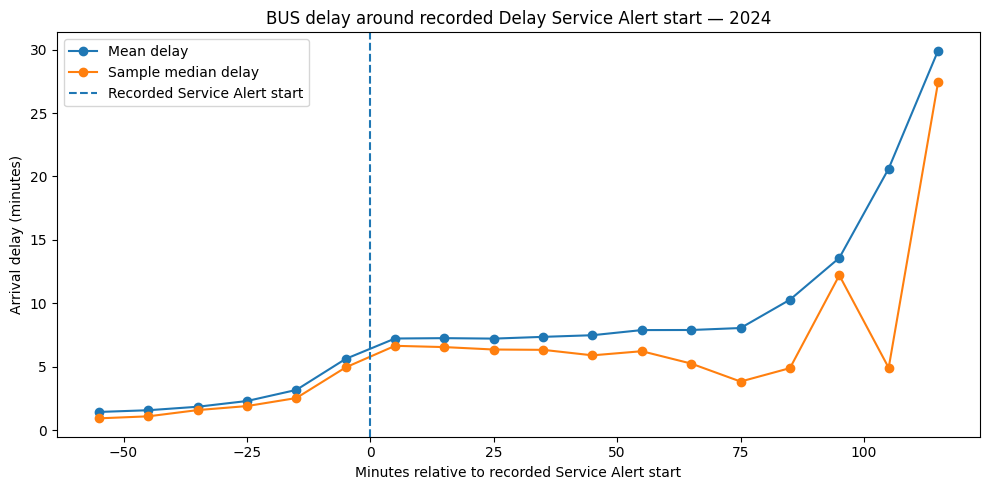

In [ ]:
# ============================================================
# BUILD CORRECTED RESULTS
# ============================================================

# ============================================================
# A. ACTIVE ALERT PERIOD COMPARISON
# ============================================================

comparison_rows = []


for label in [
    "Matching Delay alert active",
    "No matching Delay alert active"
]:

    count = (
        comparison_totals[
            label
        ]["count"]
    )

    exact_mean = (
        comparison_totals[
            label
        ]["sum_delay"]
        / count
    )


    if comparison_samples[label]:

        values = np.concatenate(
            comparison_samples[
                label
            ]
        )

        sample_median = np.median(
            values
        )

        sample_p95 = np.percentile(
            values,
            95
        )

        sample_count = len(
            values
        )

    else:

        sample_median = np.nan
        sample_p95 = np.nan
        sample_count = 0


    comparison_rows.append({
        "comparison_group":
            label,
        "observation_count":
            count,
        "mean_delay_min":
            exact_mean,
        "sample_count":
            sample_count,
        "sample_median_delay_min":
            sample_median,
        "sample_p95_delay_min":
            sample_p95
    })


alert_delay_comparison = pd.DataFrame(
    comparison_rows
)


display(
    alert_delay_comparison.round(2)
)


alert_mean = (
    alert_delay_comparison.loc[
        alert_delay_comparison[
            "comparison_group"
        ]
        == "Matching Delay alert active",
        "mean_delay_min"
    ]
    .iloc[0]
)


non_alert_mean = (
    alert_delay_comparison.loc[
        alert_delay_comparison[
            "comparison_group"
        ]
        == "No matching Delay alert active",
        "mean_delay_min"
    ]
    .iloc[0]
)


print(
    "\nDifference in mean delay:",
    f"{alert_mean - non_alert_mean:.2f} min"
)


# Comparison figure
plt.figure(
    figsize=(7, 5)
)

plt.bar(
    alert_delay_comparison[
        "comparison_group"
    ],
    alert_delay_comparison[
        "mean_delay_min"
    ]
)

plt.ylabel(
    "Mean arrival delay (minutes)"
)

plt.title(
    "BUS delay during matching recorded Delay-alert periods"
)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "delay_during_recorded_alert_periods.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# B. EVENT-CENTRED RECORDED-START ANALYSIS
# ============================================================

event_centered_rows = []


for bin_start in bin_starts:

    bin_start = int(
        bin_start
    )

    count = (
        bin_summary[
            bin_start
        ]["count"]
    )

    sum_delay = (
        bin_summary[
            bin_start
        ]["sum_delay"]
    )

    mean_delay = (
        sum_delay / count
        if count > 0
        else np.nan
    )


    if bin_samples[
        bin_start
    ]:

        values = np.concatenate(
            bin_samples[
                bin_start
            ]
        )

        sample_count = len(
            values
        )

        sample_median = np.median(
            values
        )

    else:

        sample_count = 0
        sample_median = np.nan


    event_centered_rows.append({
        "bin_start_min":
            bin_start,
        "bin_end_min":
            bin_start + BIN_WIDTH_MIN,
        "bin_mid_min":
            bin_start + BIN_WIDTH_MIN / 2,
        "observation_count":
            count,
        "mean_delay_min":
            mean_delay,
        "sample_count":
            sample_count,
        "sample_median_delay_min":
            sample_median
    })


event_centered_delay = pd.DataFrame(
    event_centered_rows
)


display(
    event_centered_delay.round(2)
)


print(
    "\nEvent-centred observations:",
    f"{total_event_centered_observations:,}"
)

print(
    "Unique Delay events represented:",
    f"{len(matched_event_ids):,}"
)


# ------------------------------------------------------------
# Compact pre-start summary
# ------------------------------------------------------------

pre_start = (
    event_centered_delay[
        event_centered_delay[
            "bin_end_min"
        ] <= 0
    ]
    .copy()
)


early_reference = pre_start[
    (
        pre_start["bin_start_min"]
        >= -60
    )
    &
    (
        pre_start["bin_end_min"]
        <= -30
    )
]


reference_mean = np.average(
    early_reference[
        "mean_delay_min"
    ],
    weights=early_reference[
        "observation_count"
    ]
)


key_pre_start = (
    pre_start[
        pre_start[
            "bin_start_min"
        ].isin(
            [
                -30,
                -20,
                -10
            ]
        )
    ][
        [
            "bin_start_min",
            "bin_end_min",
            "observation_count",
            "mean_delay_min",
            "sample_median_delay_min"
        ]
    ]
)


print(
    "\nEarly reference mean "
    "(-60 to -30 min):",
    f"{reference_mean:.2f} min"
)

print(
    "\nFinal 30 minutes before recorded start:"
)

display(
    key_pre_start.round(2)
)


# ------------------------------------------------------------
# Event-centred figure
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    event_centered_delay[
        "bin_mid_min"
    ],
    event_centered_delay[
        "mean_delay_min"
    ],
    marker="o",
    label="Mean delay"
)

plt.plot(
    event_centered_delay[
        "bin_mid_min"
    ],
    event_centered_delay[
        "sample_median_delay_min"
    ],
    marker="o",
    label="Sample median delay"
)

plt.axvline(
    0,
    linestyle="--",
    label="Recorded Service Alert start"
)

plt.xlabel(
    "Minutes relative to recorded Service Alert start"
)

plt.ylabel(
    "Arrival delay (minutes)"
)

plt.title(
    "BUS delay around recorded Delay Service Alert start — 2024"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "delay_around_recorded_alert_start.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE RESULTS
# ============================================================

alert_delay_comparison.to_csv(
    os.path.join(
        submission_folder,
        "alert_period_delay_comparison.csv"
    ),
    index=False
)

event_centered_delay.to_csv(
    os.path.join(
        submission_folder,
        "event_centered_delay_corrected.csv"
    ),
    index=False
)

The corrected event-centred analysis still shows a clear increase in BUS arrival delay before the recorded Service Alert `start`.

The weighted mean delay during the earlier **−60 to −30 minute** period is about **1.70 minutes**. It rises to **2.30 minutes** at −30 to −20 minutes, **3.17 minutes** at −20 to −10 minutes, and **5.62 minutes** during the final 10 minutes before the recorded start.

The increase therefore becomes most pronounced during the final **20 minutes** before the recorded Service Alert start. This pattern remains after aligning each delay observation to the time when the delay is actually observed, rather than to the scheduled arrival time.

Together with the timestamp audit, which showed that the recorded `start` is usually very close to the alert's first insertion into the available dataset, this supports using `start` as the temporal reference for the prediction task. The analysis does not establish the physical onset of the underlying disruption or the exact time at which passengers first received the alert.

In [ ]:
# ============================================================
# CHECK ACTIVE ALERT VS NO MATCHING ALERT
# ============================================================

display(
    alert_delay_comparison.round(2)
)

alert_row = alert_delay_comparison[
    alert_delay_comparison["comparison_group"]
    == "Matching Delay alert active"
].iloc[0]

non_alert_row = alert_delay_comparison[
    alert_delay_comparison["comparison_group"]
    == "No matching Delay alert active"
].iloc[0]

print(
    "\nDifference in mean delay:",
    f"{alert_row['mean_delay_min'] - non_alert_row['mean_delay_min']:.2f} min"
)

print(
    "Difference in sample median:",
    f"{alert_row['sample_median_delay_min'] - non_alert_row['sample_median_delay_min']:.2f} min"
)

,comparison_group,observation_count,mean_delay_min,sample_count,sample_median_delay_min,sample_p95_delay_min
0,Matching Delay alert active,2352108,7.27,23548,6.43,16.98
1,No matching Delay alert active,68129542,1.70,681272,1.25,6.43



Difference in mean delay: 5.57 min
Difference in sample median: 5.18 min


BUS observations occurring during a matching recorded Delay-alert period show substantially higher arrival delay than observations in the same relevant trip/trip-stop scope when no matching Delay alert is active.

Using the corrected observation time, mean delay is **7.27 minutes** during matching Delay-alert periods compared with **1.70 minutes** without a matching active Delay alert, a difference of **5.57 minutes**. The sample medians show the same pattern (**6.43 vs 1.25 minutes**), indicating that the difference is not driven only by a small number of extreme observations.

This relationship is descriptive rather than causal. A Service Alert does not cause the delay, and the comparison group represents the absence of a matching active Delay alert rather than guaranteed normal operation.

## 7. Problem formulation

The final modelling task is a **supervised binary classification problem** using network-wide Stockholm BUS data.

The modelling unit is one BUS trip-stop observation at time \(t\). The target is whether the recorded `start` of a trip-linked BUS Delay Service Alert occurs within the next **20 minutes**.

Label definition:

- **Positive (1):** no matching Delay alert is currently active and a matching recorded alert `start` occurs within the next 20 minutes.
- **Excluded:** a matching Delay alert is already active, or the next recorded alert `start` occurs 20–30 minutes ahead.
- **Negative (0):** no matching Delay alert is currently active and no matching recorded alert `start` occurs within the next 30 minutes.

Only information available at or before time \(t\) is used as model input.

The data are split chronologically:

- **Training:** January–August 2024
- **Validation:** September–October 2024
- **Test:** November–December 2024

## 8. Modelling dataset and feature engineering

The modelling dataset is constructed from the cleaned BUS GTFS-RT observations and the trip-linked Delay Service Alerts.

Each row represents one BUS trip-stop observation. Features include the current and recent same-trip delay pattern, position within the trip, hour, weekday, line and direction. The observation time is defined as the scheduled arrival time plus the observed arrival delay, so only information available at or before that time is used.

To keep the dataset manageable, alert-related trip-days and the preceding trip-day are retained in full, while 3% of the remaining trip-days are selected deterministically. The resulting class balance therefore reflects the **sampled modelling dataset, not the real-world frequency of Delay alerts**.

In [ ]:
# ============================================================
# MODELLING-DATASET HELPER FUNCTIONS
# ============================================================

# ------------------------------------------------------------
# 1. Prepare trip-level alert lookup
# ------------------------------------------------------------

def prepare_alerts(
    delay_stop_events_final,
    delay_trip_events_final
):

    # The final modelling target is trip-linked:
    # stop-specific and trip-wide Delay alerts both indicate
    # that the corresponding BUS trip has a Delay alert.
    alerts_trip = pd.concat(
        [
            delay_trip_events_final[
                ["trip_id", "start", "end"]
            ],
            delay_stop_events_final[
                ["trip_id", "start", "end"]
            ]
        ],
        ignore_index=True
    ).dropna()


    alerts_trip["trip_id"] = normalize_id(
        alerts_trip["trip_id"]
    )

    alerts_trip = (
        alerts_trip
        .dropna(subset=["trip_id"])
        .drop_duplicates()
    )


    for col in ["start", "end"]:

        alerts_trip[col] = pd.to_datetime(
            alerts_trip[col],
            errors="coerce"
        )


    # --------------------------------------------------------
    # Lookup for alert starts and overlapping active periods
    # --------------------------------------------------------

    trip_lookup = {}

    for trip_id, group in alerts_trip.groupby(
        "trip_id",
        sort=False
    ):

        starts = (
            group["start"]
            .astype("int64")
            .to_numpy()
        )

        ends = (
            group["end"]
            .astype("int64")
            .to_numpy()
        )

        order = np.argsort(
            starts
        )

        trip_lookup[trip_id] = (
            starts[order],
            np.maximum.accumulate(
                ends[order]
            )
        )


    # --------------------------------------------------------
    # Trip-days retained in full
    # --------------------------------------------------------

    # Keep the alert trip-day and the preceding trip-day.
    day0 = (
        alerts_trip["start"]
        .dt.normalize()
    )

    trip_ids = (
        alerts_trip["trip_id"]
        .astype(str)
    )

    alert_day_keys = set()

    for shift in [0, 1]:

        dates = (
            day0
            - pd.Timedelta(
                days=shift
            )
        ).dt.strftime(
            "%Y%m%d"
        )

        alert_day_keys.update(
            (
                trip_ids
                + "|"
                + dates
            ).tolist()
        )


    return (
        trip_lookup,
        alert_day_keys
    )


# ------------------------------------------------------------
# 2. Columns needed when scanning monthly GTFS-RT files
# ------------------------------------------------------------

MODEL_USE_COLS = [
    "date",
    "LineNumber",
    "TransportMode",
    "direction_id",
    "trip_id",
    "observed_stop_id",
    "scheduled_arrival_time_sfm",
    "observed_arrival_delay",
    "tripupdates_and_gtfs_not_merged_within_service_id",
    "tripupdates_not_merged_with_stoptimes_or_trip"
]

MODEL_KEEP_COLS = [
    "date",
    "trip_id",
    "LineNumber",
    "direction_id",
    "scheduled_arrival_time_sfm",
    "observed_arrival_delay"
]


# ------------------------------------------------------------
# 3. Monthly scan and deterministic negative sampling
# ------------------------------------------------------------

def scan_month(
    file_path,
    alert_day_keys,
    neg_pct=3,
    chunk_size=200_000
):

    kept = []

    n_raw = 0
    n_bus = 0


    for chunk in pd.read_csv(
        file_path,
        sep=";",
        compression="gzip",
        usecols=MODEL_USE_COLS,
        chunksize=chunk_size,
        low_memory=False
    ):

        n_raw += len(
            chunk
        )


        # Same BUS cleaning rules used earlier
        chunk = clean_bus_chunk(
            chunk
        )

        if chunk.empty:
            continue


        n_bus += len(
            chunk
        )


        chunk["trip_id"] = normalize_id(
            chunk["trip_id"]
        )


        chunk = chunk.dropna(
            subset=[
                "trip_id",
                "scheduled_arrival_time_sfm"
            ]
        )

        if chunk.empty:
            continue


        # ----------------------------------------
        # Trip-day key
        # ----------------------------------------

        date_int = (
            pd.to_numeric(
                chunk["date"],
                errors="coerce"
            )
            .fillna(0)
            .astype("int64")
        )

        trip_id = (
            chunk["trip_id"]
            .astype(str)
        )

        trip_day_key = (
            trip_id
            + "|"
            + date_int.astype(str)
        )


        # Keep alert-related trip-days in full
        in_alert_day = (
            trip_day_key
            .isin(
                alert_day_keys
            )
            .to_numpy()
        )


        # ----------------------------------------
        # Deterministic 3% sample of other trip-days
        # ----------------------------------------

        trip_hash = (
            pd.util.hash_pandas_object(
                trip_id,
                index=False
            )
            .to_numpy()
            .astype("uint64")
        )


        mixed_hash = (
            trip_hash
            ^
            (
                date_int
                .to_numpy()
                .astype("uint64")
                *
                np.uint64(
                    11400714819323198485
                )
            )
        )


        sampled_negative = (
            mixed_hash
            % np.uint64(100)
        ) < np.uint64(
            neg_pct
        )


        keep_mask = (
            in_alert_day
            |
            sampled_negative
        )


        chunk = (
            chunk.loc[
                keep_mask,
                MODEL_KEEP_COLS
            ]
            .copy()
        )


        if chunk.empty:
            continue


        chunk["date"] = (
            date_int
            .loc[
                chunk.index
            ]
            .to_numpy()
        )

        chunk["trip_id"] = (
            chunk["trip_id"]
            .astype(str)
        )

        chunk["LineNumber"] = (
            chunk["LineNumber"]
            .astype(str)
        )


        kept.append(
            chunk
        )


    if not kept:

        return (
            pd.DataFrame(
                columns=MODEL_KEEP_COLS
            ),
            n_raw,
            n_bus
        )


    return (
        pd.concat(
            kept,
            ignore_index=True
        ),
        n_raw,
        n_bus
    )


# ------------------------------------------------------------
# 4. Feature engineering and label construction
# ------------------------------------------------------------

def build_features_and_labels(
    df,
    trip_lookup,
    horizon=20,
    buffer_end=30
):

    df = df.copy()


    # ----------------------------------------
    # Observation time
    # ----------------------------------------

    df["service_date"] = pd.to_datetime(
        df["date"].astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    df = df.dropna(
        subset=["service_date"]
    )


    df["scheduled_ts"] = (
        df["service_date"]
        +
        pd.to_timedelta(
            df[
                "scheduled_arrival_time_sfm"
            ],
            unit="s"
        )
    )


    df["delay_min"] = (
        df[
            "observed_arrival_delay"
        ]
        / 60.0
    )


    # Time at which the observed delay is realised
    df["obs_ts"] = (
        df["scheduled_ts"]
        +
        pd.to_timedelta(
            df[
                "observed_arrival_delay"
            ],
            unit="s"
        )
    )


    # ----------------------------------------
    # Sort observations within each trip-day
    # ----------------------------------------

    df = (
        df
        .sort_values(
            [
                "trip_id",
                "date",
                "scheduled_arrival_time_sfm"
            ],
            kind="mergesort"
        )
        .reset_index(drop=True)
    )


    # ----------------------------------------
    # Recent same-trip delay history
    # ----------------------------------------

    trip_day_delay = (
        df
        .groupby(
            [
                "trip_id",
                "date"
            ],
            sort=False
        )["delay_min"]
    )


    df["prev_delay_min"] = (
        trip_day_delay.shift(1)
    )

    df["prev2_delay_min"] = (
        trip_day_delay.shift(2)
    )

    df["delay_delta"] = (
        df["delay_min"]
        -
        df["prev_delay_min"]
    )

    df["mean_delay_last3"] = (
        df[
            [
                "delay_min",
                "prev_delay_min",
                "prev2_delay_min"
            ]
        ]
        .mean(
            axis=1
        )
    )


    # Position among retained observations in the trip-day
    df["stop_idx"] = (
        trip_day_delay.cumcount()
    )


    # ----------------------------------------
    # Temporal context
    # ----------------------------------------

    df["hour"] = (
        (
            df[
                "scheduled_arrival_time_sfm"
            ]
            // 3600
        )
        % 24
    ).astype(
        "int8"
    )

    df["dow"] = (
        df[
            "service_date"
        ]
        .dt.dayofweek
        .astype("int8")
    )

    df["month"] = (
        df[
            "service_date"
        ]
        .dt.month
        .astype("int8")
    )


    # ----------------------------------------
    # Match observations to trip-linked alerts
    # ----------------------------------------

    times = (
        df["obs_ts"]
        .astype("datetime64[ns]")
        .astype("int64")
        .to_numpy()
    )


    active = np.zeros(
        len(df),
        dtype=bool
    )

    gap_min = np.full(
        len(df),
        np.inf
    )


    for trip_id, positions in (
        df
        .groupby(
            "trip_id",
            sort=False
        )
        .indices
        .items()
    ):

        lookup = trip_lookup.get(
            trip_id
        )

        if lookup is None:
            continue


        starts, cumulative_ends = (
            lookup
        )


        trip_times = (
            times[
                positions
            ]
        )


        # First alert start strictly after observation time
        next_index = np.searchsorted(
            starts,
            trip_times,
            side="right"
        )


        # ----------------------------------------
        # Is an alert already active?
        # ----------------------------------------

        previous_index = (
            next_index - 1
        )

        valid_previous = (
            previous_index >= 0
        )

        trip_active = np.zeros(
            len(positions),
            dtype=bool
        )


        trip_active[
            valid_previous
        ] = (
            cumulative_ends[
                previous_index[
                    valid_previous
                ]
            ]
            >=
            trip_times[
                valid_previous
            ]
        )


        active[
            positions
        ] = (
            trip_active
        )


        # ----------------------------------------
        # Time until next recorded alert start
        # ----------------------------------------

        has_next = (
            next_index
            < len(starts)
        )


        trip_gap = np.full(
            len(positions),
            np.inf
        )


        trip_gap[
            has_next
        ] = (
            starts[
                next_index[
                    has_next
                ]
            ]
            -
            trip_times[
                has_next
            ]
        ) / 6e10


        gap_min[
            positions
        ] = (
            trip_gap
        )


    # ----------------------------------------
    # Binary label
    # ----------------------------------------

    label = np.full(
        len(df),
        -1,
        dtype="int8"
    )


    # Positive: recorded alert start in next 20 min
    label[
        (~active)
        &
        (gap_min <= horizon)
    ] = 1


    # Negative: no alert start within next 30 min
    label[
        (~active)
        &
        (gap_min > buffer_end)
    ] = 0


    df["label"] = (
        label
    )


    # Diagnostic only; not used as a predictor
    df["gap_min"] = (
        np.where(
            np.isinf(
                gap_min
            ),
            np.nan,
            gap_min
        )
        .astype("float32")
    )


    # Exclude:
    # - already-active alert observations
    # - 20–30 min ambiguity buffer
    # - first observation of a trip, which has no delay history
    out = df[
        (df["label"] >= 0)
        &
        df[
            "prev_delay_min"
        ].notna()
    ].copy()


    final_columns = [
        "month",
        "dow",
        "hour",
        "LineNumber",
        "direction_id",
        "stop_idx",
        "delay_min",
        "prev_delay_min",
        "prev2_delay_min",
        "delay_delta",
        "mean_delay_last3",
        "gap_min",
        "label"
    ]


    out = (
        out[
            final_columns
        ]
        .reset_index(drop=True)
    )


    for col in [
        "delay_min",
        "prev_delay_min",
        "prev2_delay_min",
        "delay_delta",
        "mean_delay_last3"
    ]:

        out[col] = (
            out[col]
            .astype("float32")
        )


    out["stop_idx"] = (
        out["stop_idx"]
        .astype("int16")
    )


    return out, {
        "rows_in":
            len(df),

        "active_excluded":
            int(
                active.sum()
            ),

        "buffer_excluded":
            int(
                (
                    (~active)
                    &
                    (gap_min > horizon)
                    &
                    (gap_min <= buffer_end)
                ).sum()
            )
    }

In [ ]:
# ============================================================
# BUILD MODELLING DATASET MONTH BY MONTH
# ============================================================

dataset_folder = os.path.join(
    modeling_folder,
    "monthly"
)

os.makedirs(
    dataset_folder,
    exist_ok=True
)


# Build alert lookup
trip_lookup, alert_day_keys = prepare_alerts(
    delay_stop_events_final,
    delay_trip_events_final
)


print(
    "Trips with Delay-alert lookup:",
    f"{len(trip_lookup):,}"
)

print(
    "Alert-related trip-day keys:",
    f"{len(alert_day_keys):,}"
)


# ------------------------------------------------------------
# Process all 12 months
# ------------------------------------------------------------

monthly_build_summary = []


for file_path in monthly_files:

    file_name = os.path.basename(
        file_path
    )

    month = int(
        file_name[12:14]
    )


    output_path = os.path.join(
        dataset_folder,
        f"modeling_month_{month:02d}.parquet"
    )


    start_time = time.time()


    sampled, n_raw, n_bus = scan_month(
        file_path,
        alert_day_keys,
        neg_pct=3
    )


    modelling_month, info = (
        build_features_and_labels(
            sampled,
            trip_lookup,
            horizon=20,
            buffer_end=30
        )
    )


    modelling_month.to_parquet(
        output_path,
        index=False
    )


    monthly_build_summary.append({
        "month":
            month,

        "raw_rows":
            n_raw,

        "usable_bus_rows":
            n_bus,

        "sampled_rows":
            len(sampled),

        "final_rows":
            len(modelling_month),

        "positive_rows":
            int(
                modelling_month[
                    "label"
                ].sum()
            ),

        "active_excluded":
            info[
                "active_excluded"
            ],

        "buffer_excluded":
            info[
                "buffer_excluded"
            ],

        "seconds":
            round(
                time.time()
                -
                start_time
            )
    })


    print(
        f"Month {month:02d} complete — "
        f"{len(modelling_month):,} final rows"
    )


    del sampled
    del modelling_month

    gc.collect()


monthly_build_summary = (
    pd.DataFrame(
        monthly_build_summary
    )
    .sort_values("month")
    .reset_index(drop=True)
)


display(
    monthly_build_summary
)

Trips with Delay-alert lookup: 36,234
Alert-related trip-day keys: 258,859
Month 01 complete — 747,838 final rows
Month 02 complete — 646,962 final rows
Month 03 complete — 663,317 final rows
Month 04 complete — 625,896 final rows
Month 05 complete — 630,922 final rows
Month 06 complete — 564,832 final rows
Month 07 complete — 572,102 final rows
Month 08 complete — 624,962 final rows
Month 09 complete — 652,128 final rows
Month 10 complete — 659,824 final rows
Month 11 complete — 589,386 final rows
Month 12 complete — 533,919 final rows


,month,raw_rows,usable_bus_rows,sampled_rows,final_rows,positive_rows,active_excluded,buffer_excluded,seconds
0,1,18659047,15591049,1071243,747838,69541,262553,19717,109
1,2,17687762,13845220,919695,646962,66606,217996,19664,96
2,3,18354274,14377105,936271,663317,72089,216273,20876,99
3,4,18168030,13700634,875986,625896,63737,197925,18332,96
4,5,18616461,13971130,895294,630922,66645,210943,19007,98
5,6,16997406,13350406,787805,564832,54161,177348,15110,93
6,7,17123357,13654079,752703,572102,44631,137476,13282,97
7,8,17747633,14282329,855701,624962,60406,179488,17313,97
8,9,17847744,14665068,920335,652128,64952,214152,17692,99
9,10,18782011,14647427,924033,659824,62498,210527,17445,101


In [ ]:
# ============================================================
# MERGE MONTHLY MODELLING DATASETS
# ============================================================

monthly_model_files = sorted(
    glob.glob(
        os.path.join(
            dataset_folder,
            "modeling_month_*.parquet"
        )
    )
)


modeling_data = pd.concat(
    [
        pd.read_parquet(
            file
        )
        for file in monthly_model_files
    ],
    ignore_index=True
)


modeling_dataset_file = os.path.join(
    modeling_folder,
    "modeling_dataset.parquet"
)


modeling_data.to_parquet(
    modeling_dataset_file,
    index=False
)


# ------------------------------------------------------------
# Overall class balance
# ------------------------------------------------------------

class_summary = (
    modeling_data[
        "label"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "label"
    )
    .reset_index(
        name="row_count"
    )
)


class_summary[
    "percent"
] = (
    class_summary[
        "row_count"
    ]
    /
    len(
        modeling_data
    )
    * 100
)


print(
    "Final modelling dataset:",
    f"{len(modeling_data):,} rows"
)

display(
    class_summary.round(2)
)


# ------------------------------------------------------------
# Monthly class balance
# ------------------------------------------------------------

monthly_class_balance = (
    modeling_data
    .groupby(
        "month"
    )[
        "label"
    ]
    .agg(
        rows="size",
        positive_rate="mean"
    )
    .reset_index()
)


monthly_class_balance[
    "positive_percent"
] = (
    monthly_class_balance[
        "positive_rate"
    ]
    * 100
)


display(
    monthly_class_balance[
        [
            "month",
            "rows",
            "positive_percent"
        ]
    ].round(2)
)

Final modelling dataset: 7,512,088 rows


,label,row_count,percent
0,0,6775904,90.2
1,1,736184,9.8


,month,rows,positive_percent
0,1,747838,9.30
1,2,646962,10.30
2,3,663317,10.87
3,4,625896,10.18
4,5,630922,10.56
5,6,564832,9.59
6,7,572102,7.80
7,8,624962,9.67
8,9,652128,9.96
9,10,659824,9.47


The final modelling dataset contains **7,512,088 BUS trip-stop observations**, of which **736,184 (9.8%)** are labelled positive.

This positive rate reflects the **sampled modelling dataset rather than the real-world frequency of Delay Service Alerts**, because alert-related trip-days are retained more completely while only 3% of ordinary trip-days are sampled.

## 9. Modelling-dataset EDA

A short exploratory check is performed on the final modelling table before the chronological split. The focus is limited to class balance, missing values and the numerical predictor distributions.

In [ ]:
# ============================================================
# MODELLING-DATASET EDA
# ============================================================

# Final predictor variables used by the models
numeric_features = [
    "delay_min",
    "prev_delay_min",
    "prev2_delay_min",
    "delay_delta",
    "mean_delay_last3",
    "stop_idx",
    "hour",
    "dow"
]

categorical_features = [
    "LineNumber",
    "direction_id"
]

model_features = (
    numeric_features
    + categorical_features
)


# ------------------------------------------------------------
# 1. Overall class balance
# ------------------------------------------------------------

class_balance = (
    modeling_data["label"]
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .reset_index(name="row_count")
)

class_balance["percent"] = (
    class_balance["row_count"]
    / len(modeling_data)
    * 100
)

print("Overall class balance:")

display(
    class_balance.round(2)
)


# ------------------------------------------------------------
# 2. Class balance by month
# ------------------------------------------------------------

monthly_balance = (
    modeling_data
    .groupby("month")["label"]
    .agg(
        rows="size",
        positives="sum",
        positive_rate="mean"
    )
    .reset_index()
)

monthly_balance["positive_percent"] = (
    monthly_balance["positive_rate"]
    * 100
)

print("\nClass balance by month:")

display(
    monthly_balance[
        [
            "month",
            "rows",
            "positives",
            "positive_percent"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# 3. Missing values after feature construction
# ------------------------------------------------------------

missing_summary = pd.DataFrame({
    "feature": model_features,
    "missing_count": [
        modeling_data[col].isna().sum()
        for col in model_features
    ]
})

missing_summary["missing_percent"] = (
    missing_summary["missing_count"]
    / len(modeling_data)
    * 100
)

print("\nMissing values in model predictors:")

display(
    missing_summary.round(2)
)

Overall class balance:


,label,row_count,percent
0,0,6775904,90.2
1,1,736184,9.8



Class balance by month:


,month,rows,positives,positive_percent
0,1,747838,69541,9.30
1,2,646962,66606,10.30
2,3,663317,72089,10.87
3,4,625896,63737,10.18
4,5,630922,66645,10.56
5,6,564832,54161,9.59
6,7,572102,44631,7.80
7,8,624962,60406,9.67
8,9,652128,64952,9.96
9,10,659824,62498,9.47



Missing values in model predictors:


,feature,missing_count,missing_percent
0,delay_min,0,0.00
1,prev_delay_min,0,0.00
2,prev2_delay_min,399754,5.32
3,delay_delta,0,0.00
4,mean_delay_last3,0,0.00
5,stop_idx,0,0.00
6,hour,0,0.00
7,dow,0,0.00
8,LineNumber,0,0.00
9,direction_id,0,0.00


In [ ]:
# ============================================================
# NUMERICAL PREDICTOR SUMMARY
# ============================================================

descriptive_features = [
    "delay_min",
    "prev_delay_min",
    "prev2_delay_min",
    "delay_delta",
    "mean_delay_last3",
    "stop_idx"
]


descriptive_summary = (
    modeling_data[
        descriptive_features
    ]
    .describe(
        percentiles=[
            0.50,
            0.95,
            0.99
        ]
    )
    .T
    [
        [
            "count",
            "mean",
            "std",
            "50%",
            "95%",
            "99%",
            "min",
            "max"
        ]
    ]
)


descriptive_summary = (
    descriptive_summary
    .rename(
        columns={
            "50%": "median",
            "95%": "p95",
            "99%": "p99"
        }
    )
)


display(
    descriptive_summary.round(2)
)

,count,mean,std,median,p95,p99,min,max
delay_min,7512088.0,2.21,4.12,1.55,7.53,14.78,-109.07,360.00
prev_delay_min,7512088.0,2.12,4.02,1.50,7.28,14.27,-119.58,360.00
prev2_delay_min,7112334.0,2.11,3.99,1.50,7.17,14.20,-119.58,360.00
delay_delta,7512088.0,0.10,1.59,0.00,1.77,4.82,-370.42,345.87
mean_delay_last3,7512088.0,2.12,3.92,1.46,7.21,14.18,-108.31,360.00
stop_idx,7512088.0,14.06,12.42,11.00,37.00,62.00,1.00,129.00


The modelling dataset has a moderate sampled class imbalance, with **9.8% positive observations**, and the positive share remains relatively stable across months.

All final predictors are complete except `prev2_delay_min`, which is missing for **5.32%** of observations because some trip-stop observations do not yet have two previous delay measurements. These remaining missing history values are handled during model preprocessing.

The modelling sample retains the wide range of delay values observed in the operational data. No additional outlier trimming is applied. Because alert-related trip-days are sampled more heavily than ordinary trip-days, the delay distribution and class prevalence in this modelling table should not be interpreted as representative of the full BUS network.

## 10. Chronological split and preprocessing

The modelling data are split chronologically to reflect prediction on future periods:

- **Training:** January–August 2024
- **Validation:** September–October 2024
- **Test:** November–December 2024

A fixed random sample of **1,000,000 training observations** is used for model fitting to keep computation manageable. Validation and test observations are kept in full from the sampled modelling dataset.

Numerical predictors are standardised for Logistic Regression but left unchanged for the tree-based models. `LineNumber` and `direction_id` are treated as categorical variables and one-hot encoded. All learned preprocessing steps are fitted using the training data only.

In [ ]:
# ============================================================
# CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# ------------------------------------------------------------
# Final predictor groups
# ------------------------------------------------------------

num = [
    "delay_min",
    "prev_delay_min",
    "prev2_delay_min",
    "delay_delta",
    "mean_delay_last3",
    "stop_idx",
    "hour",
    "dow"
]

cat = [
    "LineNumber",
    "direction_id"
]

features = num + cat


# ------------------------------------------------------------
# Prepare categorical variables
# ------------------------------------------------------------

modeling_data["LineNumber"] = (
    modeling_data["LineNumber"]
    .astype(str)
)

modeling_data["direction_id"] = (
    modeling_data["direction_id"]
    .astype(str)
)


# ------------------------------------------------------------
# Handle remaining recent-history missing values
# ------------------------------------------------------------

# At this stage only prev2_delay_min is expected to contain
# missing values, but the same rule is applied consistently
# to all recent-history variables used in the original model.
#
# This is a row-level deterministic replacement rather than
# a quantity learned from the full dataset.

history_columns = [
    "prev_delay_min",
    "prev2_delay_min",
    "delay_delta",
    "mean_delay_last3"
]

for col in history_columns:

    modeling_data[col] = (
        modeling_data[col]
        .fillna(
            modeling_data["delay_min"]
        )
    )


# ------------------------------------------------------------
# Chronological split
# ------------------------------------------------------------

train_full = modeling_data[
    modeling_data["month"] <= 8
].copy()

val = modeling_data[
    (modeling_data["month"] >= 9)
    &
    (modeling_data["month"] <= 10)
].copy()

test = modeling_data[
    modeling_data["month"] >= 11
].copy()


# ------------------------------------------------------------
# Fixed 1,000,000-row training sample
# ------------------------------------------------------------

train = train_full.sample(
    n=min(
        len(train_full),
        1_000_000
    ),
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# Compact split summary
# ------------------------------------------------------------

split_summary = pd.DataFrame({
    "split": [
        "Training period (full)",
        "Training rows used for fitting",
        "Validation",
        "Test"
    ],
    "months": [
        "Jan–Aug",
        "Jan–Aug",
        "Sep–Oct",
        "Nov–Dec"
    ],
    "rows": [
        len(train_full),
        len(train),
        len(val),
        len(test)
    ],
    "positive_percent": [
        train_full["label"].mean() * 100,
        train["label"].mean() * 100,
        val["label"].mean() * 100,
        test["label"].mean() * 100
    ]
})

display(
    split_summary.round(2)
)


# Final missing-value check
print("Missing predictor values after preprocessing:")
print(
    modeling_data[
        features
    ]
    .isna()
    .sum()
)

,split,months,rows,positive_percent
0,Training period (full),Jan–Aug,5076831,9.81
1,Training rows used for fitting,Jan–Aug,1000000,9.77
2,Validation,Sep–Oct,1311952,9.71
3,Test,Nov–Dec,1123305,9.87


Missing predictor values after preprocessing:
delay_min           0
prev_delay_min      0
prev2_delay_min     0
delay_delta         0
mean_delay_last3    0
stop_idx            0
hour                0
dow                 0
LineNumber          0
direction_id        0
dtype: int64


In [ ]:
# ============================================================
# MODEL-SPECIFIC PREPROCESSING
# ============================================================

# ------------------------------------------------------------
# Logistic Regression
#
# Numeric variables are standardised.
# Rare categorical values are grouped during fitting.
# ------------------------------------------------------------

pre_lr = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        num
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=50
        ),
        cat
    )
])


# ------------------------------------------------------------
# Random Forest
#
# Tree models do not require numeric scaling.
# ------------------------------------------------------------

pre_rf = ColumnTransformer([
    (
        "numeric",
        "passthrough",
        num
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=50
        ),
        cat
    )
])


# ------------------------------------------------------------
# Histogram Gradient Boosting
#
# Numeric variables remain unchanged.
#
# HistGradientBoostingClassifier requires dense input here,
# so categorical encoding uses a higher rare-category
# threshold to keep the matrix manageable.
# ------------------------------------------------------------

pre_gb = ColumnTransformer([
    (
        "numeric",
        "passthrough",
        num
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=2000,
            sparse_output=False,
            dtype=np.float32
        ),
        cat
    )
])


# ------------------------------------------------------------
# Current-delay-only baseline
# ------------------------------------------------------------

pre_baseline = ColumnTransformer([
    (
        "current_delay",
        "passthrough",
        ["delay_min"]
    )
])


print("Preprocessing pipelines defined.")

Preprocessing pipelines defined.


The chronological split produces similar sampled positive rates across training, validation and test periods. The remaining missing recent-history values are resolved before model fitting, leaving a complete predictor matrix.

The scaler and categorical encoders are defined here but are fitted only as part of each model pipeline using the training data, preventing information from the validation or test periods from entering preprocessing.

## 11. Model training and evaluation

Four classifiers are compared:

- **Current-delay baseline:** Logistic Regression using only the current delay.
- **Logistic Regression:** linear model using all final predictors.
- **Random Forest:** non-linear ensemble model.
- **Histogram Gradient Boosting:** sequential tree ensemble for non-linear relationships.

Class weighting is used to address the sampled class imbalance. Each model is fitted using the fixed training sample. Its decision threshold is then selected on the **validation set** by maximising F1 score, and that threshold is applied unchanged to the **November–December test set**.

Final evaluation uses precision, recall, F1, ROC-AUC and PR-AUC (calculated as average precision).

In [ ]:
# ============================================================
# MODEL DEFINITIONS
# ============================================================

models = {
    "Current-delay baseline": Pipeline([
        (
            "preprocessing",
            pre_baseline
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=300
            )
        )
    ]),

    "Logistic Regression": Pipeline([
        (
            "preprocessing",
            pre_lr
        ),
        (
            "model",
            LogisticRegression(
                max_iter=300,
                class_weight="balanced"
            )
        )
    ]),

    "Random Forest": Pipeline([
        (
            "preprocessing",
            pre_rf
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=80,
                max_depth=14,
                min_samples_leaf=50,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        )
    ]),

    "Gradient Boosting": Pipeline([
        (
            "preprocessing",
            pre_gb
        ),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.1,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ])
}


# ============================================================
# VALIDATION-BASED THRESHOLD SELECTION
# ============================================================

def best_f1_threshold(
    y_true,
    probabilities
):

    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probabilities
        )
    )

    # precision and recall contain one extra value
    # compared with the threshold array.
    f1 = (
        2
        * precision[:-1]
        * recall[:-1]
        /
        np.maximum(
            precision[:-1]
            + recall[:-1],
            1e-9
        )
    )

    best_index = np.argmax(
        f1
    )

    return (
        thresholds[
            best_index
        ],
        f1[
            best_index
        ]
    )


print("Models defined:")
for name in models:
    print("-", name)

Models defined:
- Current-delay baseline
- Logistic Regression
- Random Forest
- Gradient Boosting


In [ ]:
# ============================================================
# TRAIN, VALIDATE AND TEST MODELS
# ============================================================

results_rows = []

fitted_models = {}

test_probabilities = {}

validation_probabilities = {}


for name, model in models.items():

    print(
        f"\nTraining: {name}"
    )

    start_time = time.time()


    # --------------------------------------------------------
    # 1. Fit using training data only
    # --------------------------------------------------------

    model.fit(
        train[features],
        train["label"]
    )


    # --------------------------------------------------------
    # 2. Validation probabilities
    # --------------------------------------------------------

    val_prob = (
        model.predict_proba(
            val[features]
        )[:, 1]
    )

    validation_probabilities[
        name
    ] = val_prob


    # --------------------------------------------------------
    # 3. Select threshold using validation F1 only
    # --------------------------------------------------------

    threshold, validation_f1 = (
        best_f1_threshold(
            val["label"],
            val_prob
        )
    )


    # --------------------------------------------------------
    # 4. Apply unchanged threshold to test data
    # --------------------------------------------------------

    test_prob = (
        model.predict_proba(
            test[features]
        )[:, 1]
    )

    test_pred = (
        test_prob
        >= threshold
    ).astype(int)


    # --------------------------------------------------------
    # 5. Test-set metrics
    # --------------------------------------------------------

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            test["label"],
            test_pred,
            average="binary",
            zero_division=0
        )
    )

    roc_auc = roc_auc_score(
        test["label"],
        test_prob
    )

    # average_precision_score is used as the
    # project PR-AUC / Average Precision measure
    pr_auc = average_precision_score(
        test["label"],
        test_prob
    )


    elapsed = (
        time.time()
        - start_time
    )


    results_rows.append({
        "model":
            name,

        "threshold":
            threshold,

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1,

        "roc_auc":
            roc_auc,

        "pr_auc":
            pr_auc,

        "validation_f1":
            validation_f1,

        "training_eval_seconds":
            elapsed
    })


    fitted_models[
        name
    ] = model

    test_probabilities[
        name
    ] = test_prob


    print(
        f"Threshold: {threshold:.4f}"
    )

    print(
        f"Test F1: {f1:.4f}"
    )

    print(
        f"Completed in {elapsed:.0f} s"
    )


# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

model_results = (
    pd.DataFrame(
        results_rows
    )
    .sort_values(
        "pr_auc",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    model_results[
        [
            "model",
            "threshold",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "pr_auc"
        ]
    ].round(4)
)


print(
    "\nTest-set positive rate:",
    f"{test['label'].mean() * 100:.2f}%"
)


# Save results
model_results.to_csv(
    os.path.join(
        modeling_folder,
        "model_results_test.csv"
    ),
    index=False
)


Training: Current-delay baseline
Threshold: 0.5792
Test F1: 0.3974
Completed in 4 s

Training: Logistic Regression
Threshold: 0.6945
Test F1: 0.4597
Completed in 27 s

Training: Random Forest
Threshold: 0.6833
Test F1: 0.4606
Completed in 87 s

Training: Gradient Boosting
Threshold: 0.7692
Test F1: 0.5307
Completed in 469 s


,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,Gradient Boosting,0.7692,0.4814,0.5912,0.5307,0.8993,0.5224
1,Random Forest,0.6833,0.3836,0.5763,0.4606,0.8556,0.4105
2,Logistic Regression,0.6945,0.3734,0.5980,0.4597,0.8621,0.3314
3,Current-delay baseline,0.5792,0.2951,0.6079,0.3974,0.8053,0.2595



Test-set positive rate: 9.87%


The four models show clear differences in predictive performance. **Histogram Gradient Boosting performs best overall**, with the highest F1 (**0.531**), ROC-AUC (**0.899**) and PR-AUC / average precision (**0.522**).

The current-delay-only baseline performs substantially worse, with F1 **0.397** and PR-AUC **0.260**, showing that the fuller model provides much stronger discrimination than current delay alone.

The decision threshold for each model was selected on the validation set and then applied unchanged to the held-out November–December test set.

## 12. Model diagnostics

Diagnostics are performed on the held-out **November–December test set** using the best-performing model and its validation-selected decision threshold.

The analysis examines performance across current-delay levels, time of day, test month and common BUS lines. Permutation importance is also used to estimate how strongly the best model depends on each input feature.

Because the test data come from the sampled modelling dataset, subgroup positive rates and absolute precision should not be interpreted as natural operational rates.

Best model: Gradient Boosting
Validation-selected threshold: 0.7692


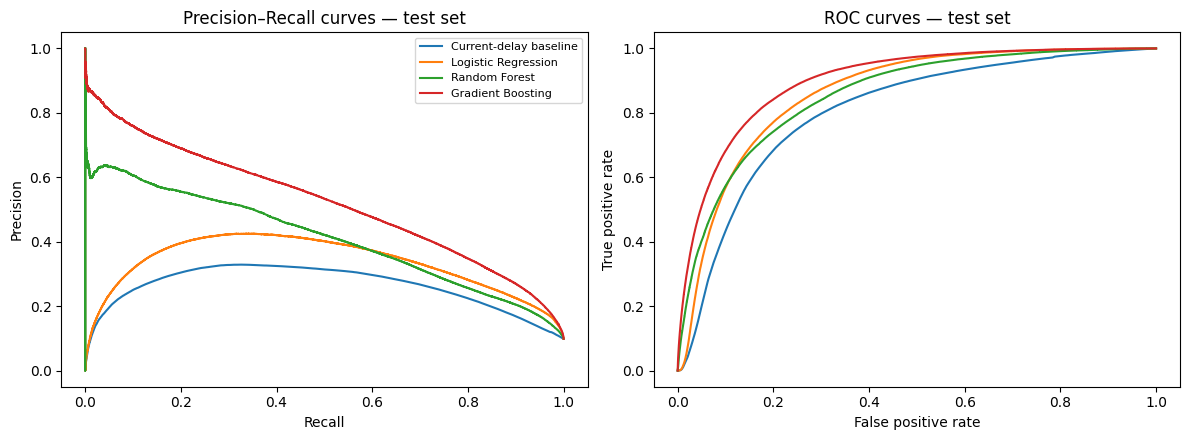

In [ ]:
# ============================================================
# MODEL COMPARISON CURVES AND BEST-MODEL TEST PREDICTIONS
# ============================================================

# Best model according to test-set PR-AUC / Average Precision
best_name = (
    model_results
    .sort_values(
        "pr_auc",
        ascending=False
    )
    .iloc[0]["model"]
)

best_model = fitted_models[
    best_name
]

best_scores = test_probabilities[
    best_name
]

best_threshold = float(
    model_results.loc[
        model_results["model"] == best_name,
        "threshold"
    ].iloc[0]
)


print(
    "Best model:",
    best_name
)

print(
    "Validation-selected threshold:",
    round(best_threshold, 4)
)


# ------------------------------------------------------------
# Precision-Recall and ROC curves
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5)
)


for name in models:

    scores = test_probabilities[
        name
    ]

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            test["label"],
            scores
        )
    )

    fpr, tpr, _ = roc_curve(
        test["label"],
        scores
    )

    axes[0].plot(
        recall_curve,
        precision_curve,
        label=name
    )

    axes[1].plot(
        fpr,
        tpr,
        label=name
    )


axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title(
    "Precision–Recall curves — test set"
)

axes[1].set_xlabel(
    "False positive rate"
)
axes[1].set_ylabel(
    "True positive rate"
)
axes[1].set_title(
    "ROC curves — test set"
)

axes[0].legend(
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "model_pr_roc_curves.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Add best-model scores and predictions to test copy
# ------------------------------------------------------------

test_diag = test.copy()

test_diag["score"] = (
    best_scores
)

test_diag["pred"] = (
    test_diag["score"]
    >= best_threshold
).astype(int)

Performance by current delay:


,n,positive_percent,precision,recall,f1
delay_bin,,,,,
≤ 0,221954.0,1.401,0.415,0.007,0.014
0–2,418994.0,3.143,0.369,0.120,0.181
2–5,320609.0,13.440,0.457,0.502,0.478
5–10,125497.0,34.505,0.519,0.846,0.643
10–20,27619.0,28.281,0.429,0.710,0.535
> 20,8632.0,5.016,0.164,0.360,0.225


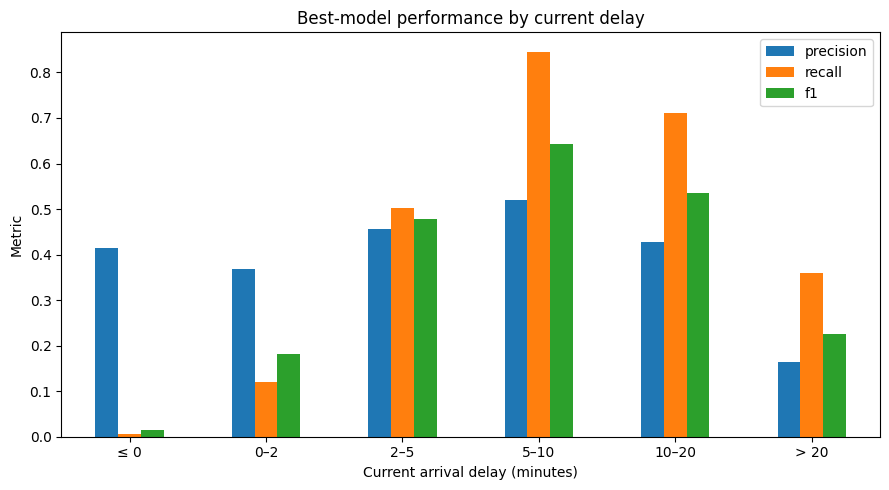


Performance by scheduled hour:


,n,positive_rate,precision,recall,f1
hour,,,,,
0,16158.0,0.015,0.470,0.362,0.409
1,9131.0,0.017,0.365,0.434,0.396
2,6930.0,0.019,0.224,0.286,0.251
3,5573.0,0.034,0.535,0.361,0.431
4,6751.0,0.065,0.366,0.635,0.464
5,24998.0,0.097,0.426,0.684,0.525
6,60783.0,0.120,0.474,0.608,0.533
7,74767.0,0.102,0.398,0.556,0.464
8,67708.0,0.081,0.324,0.563,0.411



Performance by test month:


,n,positive_rate,precision,recall,f1
month,,,,,
11,589386.0,0.101,0.468,0.579,0.518
12,533919.0,0.097,0.498,0.605,0.546


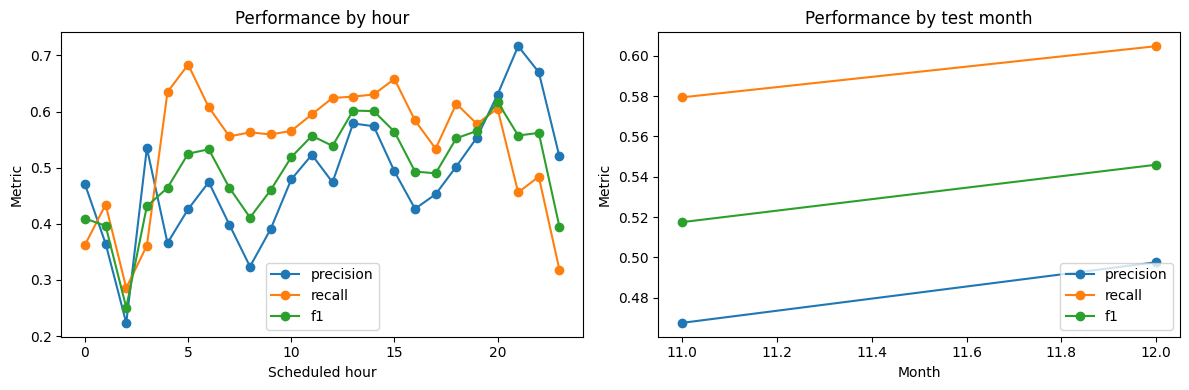


Performance for the 15 most frequent lines:


,n,positive_rate,precision,recall,f1
LineNumber,,,,,
540,11025.0,0.090,0.573,0.353,0.437
179,11581.0,0.137,0.606,0.367,0.457
119,11272.0,0.128,0.618,0.366,0.460
177,29339.0,0.257,0.457,0.520,0.487
176,44587.0,0.244,0.451,0.604,0.517
807,9694.0,0.109,0.400,0.734,0.518
514,19585.0,0.285,0.532,0.529,0.531
312,10485.0,0.204,0.498,0.648,0.563
509,10353.0,0.220,0.664,0.490,0.564


In [ ]:
# ============================================================
# SUBGROUP PERFORMANCE OF THE BEST MODEL
# ============================================================

def group_metrics(group):

    y_true = group["label"]
    y_pred = group["pred"]

    tp = int(
        (
            (y_pred == 1)
            &
            (y_true == 1)
        ).sum()
    )

    fp = int(
        (
            (y_pred == 1)
            &
            (y_true == 0)
        ).sum()
    )

    fn = int(
        (
            (y_pred == 0)
            &
            (y_true == 1)
        ).sum()
    )


    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    f1 = (
        2
        * precision
        * recall
        / (precision + recall)
        if (
            pd.notna(precision)
            and pd.notna(recall)
            and (precision + recall) > 0
        )
        else np.nan
    )


    return pd.Series({
        "n":
            len(group),

        "positive_rate":
            y_true.mean(),

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1
    })


# ============================================================
# A. PERFORMANCE BY CURRENT DELAY
# ============================================================

delay_edges = [
    -np.inf,
    0,
    2,
    5,
    10,
    20,
    np.inf
]

delay_labels = [
    "≤ 0",
    "0–2",
    "2–5",
    "5–10",
    "10–20",
    "> 20"
]


test_diag["delay_bin"] = pd.cut(
    test_diag["delay_min"],
    bins=delay_edges,
    labels=delay_labels,
    include_lowest=True
)


by_delay = (
    test_diag
    .groupby(
        "delay_bin",
        observed=True
    )
    .apply(
        group_metrics,
        include_groups=False
    )
)


by_delay["positive_percent"] = (
    by_delay["positive_rate"]
    * 100
)


print(
    "Performance by current delay:"
)

display(
    by_delay[
        [
            "n",
            "positive_percent",
            "precision",
            "recall",
            "f1"
        ]
    ].round(3)
)


# ------------------------------------------------------------
# Delay-group figure
# ------------------------------------------------------------

by_delay[
    [
        "precision",
        "recall",
        "f1"
    ]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.xlabel(
    "Current arrival delay (minutes)"
)

plt.ylabel(
    "Metric"
)

plt.title(
    "Best-model performance by current delay"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "diagnostics_by_delay.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# B. PERFORMANCE BY HOUR
# ============================================================

by_hour = (
    test_diag
    .groupby("hour")
    .apply(
        group_metrics,
        include_groups=False
    )
)


print(
    "\nPerformance by scheduled hour:"
)

display(
    by_hour.round(3)
)


# ============================================================
# C. PERFORMANCE BY TEST MONTH
# ============================================================

by_month = (
    test_diag
    .groupby("month")
    .apply(
        group_metrics,
        include_groups=False
    )
)


print(
    "\nPerformance by test month:"
)

display(
    by_month.round(3)
)


# ------------------------------------------------------------
# Hour + month figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)


by_hour[
    [
        "precision",
        "recall",
        "f1"
    ]
].plot(
    ax=axes[0],
    marker="o"
)

axes[0].set_title(
    "Performance by hour"
)

axes[0].set_xlabel(
    "Scheduled hour"
)

axes[0].set_ylabel(
    "Metric"
)


by_month[
    [
        "precision",
        "recall",
        "f1"
    ]
].plot(
    ax=axes[1],
    marker="o"
)

axes[1].set_title(
    "Performance by test month"
)

axes[1].set_xlabel(
    "Month"
)

axes[1].set_ylabel(
    "Metric"
)


plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "diagnostics_by_hour_month.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# D. PERFORMANCE BY COMMON BUS LINE
# ============================================================

top_lines = (
    test_diag[
        "LineNumber"
    ]
    .value_counts()
    .head(15)
    .index
)


by_line = (
    test_diag[
        test_diag[
            "LineNumber"
        ].isin(
            top_lines
        )
    ]
    .groupby(
        "LineNumber"
    )
    .apply(
        group_metrics,
        include_groups=False
    )
    .sort_values("f1")
)


print(
    "\nPerformance for the 15 most frequent lines:"
)

display(
    by_line.round(3)
)


# ============================================================
# SAVE SUBGROUP TABLES
# ============================================================

by_delay.to_csv(
    os.path.join(
        modeling_folder,
        "diagnostics_by_delay.csv"
    )
)

by_hour.to_csv(
    os.path.join(
        modeling_folder,
        "diagnostics_by_hour.csv"
    )
)

by_month.to_csv(
    os.path.join(
        modeling_folder,
        "diagnostics_by_month.csv"
    )
)

by_line.to_csv(
    os.path.join(
        modeling_folder,
        "diagnostics_by_line.csv"
    )
)

Permutation importance (drop in Average Precision):


,feature,importance_mean,importance_std
0,delay_min,0.3254,0.0013
1,LineNumber,0.2249,0.0034
2,stop_idx,0.1174,0.0017
3,dow,0.0250,0.0004
4,hour,0.0209,0.0005
5,mean_delay_last3,0.0111,0.0007
6,delay_delta,0.0074,0.0006
7,prev2_delay_min,0.0054,0.0001
8,direction_id,0.0010,0.0001
9,prev_delay_min,0.0009,0.0003


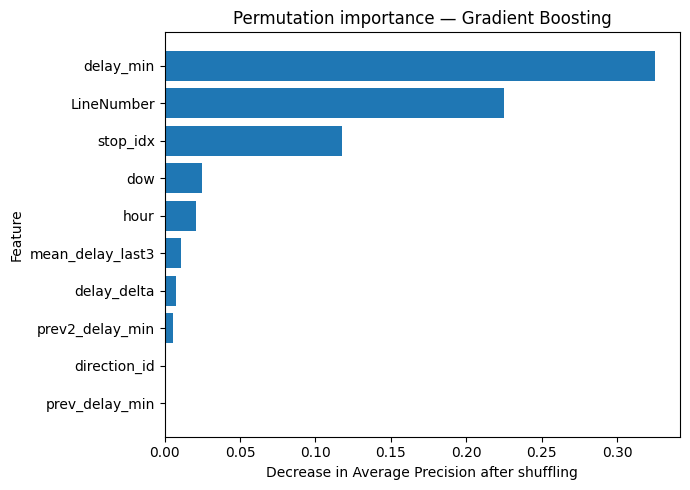

In [ ]:
# ============================================================
# PERMUTATION IMPORTANCE
# ============================================================

# Fixed 100,000-row test sample
importance_sample = test.sample(
    n=min(
        len(test),
        100_000
    ),
    random_state=RANDOM_STATE
)


permutation_result = permutation_importance(
    best_model,
    importance_sample[
        features
    ],
    importance_sample[
        "label"
    ],
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)


importance = pd.DataFrame({
    "feature":
        features,

    "importance_mean":
        permutation_result.importances_mean,

    "importance_std":
        permutation_result.importances_std
})


importance = (
    importance
    .sort_values(
        "importance_mean",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "Permutation importance "
    "(drop in Average Precision):"
)

display(
    importance.round(4)
)


# ------------------------------------------------------------
# Importance figure
# ------------------------------------------------------------

importance_plot = (
    importance
    .sort_values(
        "importance_mean"
    )
)


plt.figure(
    figsize=(7, 5)
)

plt.barh(
    importance_plot[
        "feature"
    ],
    importance_plot[
        "importance_mean"
    ]
)

plt.xlabel(
    "Decrease in Average Precision after shuffling"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Permutation importance — Gradient Boosting"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "permutation_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


importance.to_csv(
    os.path.join(
        modeling_folder,
        "permutation_importance.csv"
    ),
    index=False
)

The diagnostics show that the best model performs very differently depending on the operational situation.

Performance is strongest once a bus is already clearly delayed. For observations with **5–10 minutes of current delay**, recall reaches **0.846** and F1 **0.643**. In contrast, recall is only **0.007** for buses that are on time or early and **0.120** for delays of 0–2 minutes. The model therefore has limited ability to anticipate recorded Delay-alert starts before visible delay has developed.

Performance also varies by time of day and BUS line. F1 ranges from **0.251 at 02:00** to **0.617 at 20:00**, while the 15 most frequent lines show F1 values from approximately **0.44 to 0.71**. November and December give similar performance, although two test months are not sufficient to assess seasonal robustness.

Permutation importance shows that **current delay** is the strongest predictor, followed by **LineNumber** and **position within the trip (`stop_idx`)**. Hour and weekday contribute more modestly. Recent-delay features have relatively low individual permutation importance, but because these variables are closely related to current delay and to each other, this does not imply that they contain no useful information.

## 13. Robustness and sensitivity testing

Robustness is tested without retraining the model or changing its validation-selected decision threshold.

Three checks are used:

1. **Delay-noise robustness:** synthetic noise is added to the current and recent delay measurements, after which the derived delay-change and recent-mean features are recalculated.
2. **Recent-history sensitivity:** recent delay-history information is progressively removed to test how dependent the model is on previous trip observations.
3. **Extreme-line sensitivity:** test performance is recalculated with the previously flagged lines 908, 955 and 574 excluded.

The synthetic noise levels are stress-test scenarios and are not assumed to represent known measurement-error levels in the SL data.

In [ ]:
# ============================================================
# ROBUSTNESS / SENSITIVITY EVALUATION HELPER
# ============================================================

def evaluate_test_scenario(
    y_true,
    scores,
    threshold
):

    predictions = (
        scores >= threshold
    ).astype(int)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            predictions,
            average="binary",
            zero_division=0
        )
    )

    return {
        "n":
            len(y_true),

        "positive_rate":
            y_true.mean(),

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1,

        "roc_auc":
            roc_auc_score(
                y_true,
                scores
            ),

        "pr_auc":
            average_precision_score(
                y_true,
                scores
            )
    }


# Baseline performance of the unchanged best model
baseline_robustness = evaluate_test_scenario(
    test["label"],
    best_scores,
    best_threshold
)

print("Reference test performance:")

display(
    pd.DataFrame(
        [baseline_robustness]
    ).round(4)
)

Reference test performance:


,n,positive_rate,precision,recall,f1,roc_auc,pr_auc
0,1123305,0.0987,0.4814,0.5912,0.5307,0.8993,0.5224


Robustness to synthetic delay noise:


,noise_sd_min,n,precision,recall,f1,roc_auc,pr_auc
0,0.0,1123305,0.4814,0.5912,0.5307,0.8993,0.5224
1,0.5,1123305,0.4684,0.5850,0.5202,0.8949,0.5085
2,1.0,1123305,0.4404,0.5747,0.4987,0.8848,0.4787
3,2.0,1123305,0.3646,0.5483,0.4380,0.8538,0.4014


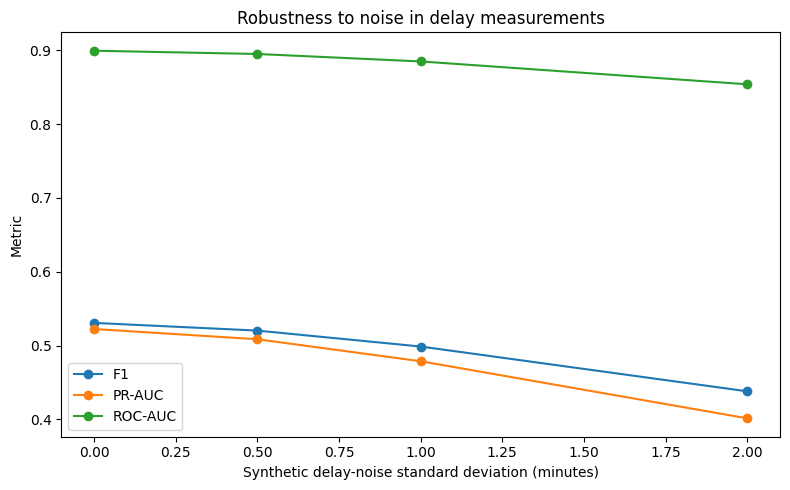

In [ ]:
# ============================================================
# ROBUSTNESS TEST 1:
# SYNTHETIC NOISE IN DELAY MEASUREMENTS
# ============================================================

noise_levels = [
    0.0,
    0.5,
    1.0,
    2.0
]

noise_results = []


for sigma in noise_levels:

    test_noise = test.copy()


    # --------------------------------------------------------
    # Add independent Gaussian noise to the three underlying
    # delay observations used by the model.
    # --------------------------------------------------------

    if sigma > 0:

        rng_noise = np.random.default_rng(
            RANDOM_STATE
            + int(sigma * 100)
        )

        test_noise["delay_min"] = (
            test_noise["delay_min"]
            +
            rng_noise.normal(
                0,
                sigma,
                len(test_noise)
            )
        )

        test_noise["prev_delay_min"] = (
            test_noise["prev_delay_min"]
            +
            rng_noise.normal(
                0,
                sigma,
                len(test_noise)
            )
        )

        test_noise["prev2_delay_min"] = (
            test_noise["prev2_delay_min"]
            +
            rng_noise.normal(
                0,
                sigma,
                len(test_noise)
            )
        )


        # Recalculate derived recent-delay features
        test_noise["delay_delta"] = (
            test_noise["delay_min"]
            -
            test_noise["prev_delay_min"]
        )

        test_noise["mean_delay_last3"] = (
            test_noise[
                [
                    "delay_min",
                    "prev_delay_min",
                    "prev2_delay_min"
                ]
            ]
            .mean(axis=1)
        )


    # --------------------------------------------------------
    # Evaluate unchanged trained model
    # --------------------------------------------------------

    scores = (
        best_model
        .predict_proba(
            test_noise[
                features
            ]
        )[:, 1]
    )


    metrics = evaluate_test_scenario(
        test_noise["label"],
        scores,
        best_threshold
    )


    metrics["noise_sd_min"] = sigma

    noise_results.append(
        metrics
    )


noise_results = (
    pd.DataFrame(
        noise_results
    )
    [
        [
            "noise_sd_min",
            "n",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "pr_auc"
        ]
    ]
)


print(
    "Robustness to synthetic delay noise:"
)

display(
    noise_results.round(4)
)


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    noise_results["noise_sd_min"],
    noise_results["f1"],
    marker="o",
    label="F1"
)

plt.plot(
    noise_results["noise_sd_min"],
    noise_results["pr_auc"],
    marker="o",
    label="PR-AUC"
)

plt.plot(
    noise_results["noise_sd_min"],
    noise_results["roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel(
    "Synthetic delay-noise standard deviation (minutes)"
)

plt.ylabel(
    "Metric"
)

plt.title(
    "Robustness to noise in delay measurements"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_folder,
        "robustness_delay_noise.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


noise_results.to_csv(
    os.path.join(
        modeling_folder,
        "robustness_delay_noise.csv"
    ),
    index=False
)

In [ ]:
# ============================================================
# ROBUSTNESS TEST 2:
# RECENT-HISTORY AVAILABILITY
# ============================================================

history_results = []


# ------------------------------------------------------------
# Scenario A — full information
# ------------------------------------------------------------

full_scores = (
    best_model
    .predict_proba(
        test[
            features
        ]
    )[:, 1]
)

metrics = evaluate_test_scenario(
    test["label"],
    full_scores,
    best_threshold
)

metrics["scenario"] = (
    "Full recent history"
)

history_results.append(
    metrics
)


# ------------------------------------------------------------
# Scenario B — second previous observation unavailable
# ------------------------------------------------------------

test_no_prev2 = test.copy()

test_no_prev2[
    "prev2_delay_min"
] = (
    test_no_prev2[
        "delay_min"
    ]
)

test_no_prev2[
    "mean_delay_last3"
] = (
    test_no_prev2[
        [
            "delay_min",
            "prev_delay_min",
            "prev2_delay_min"
        ]
    ]
    .mean(axis=1)
)


scores = (
    best_model
    .predict_proba(
        test_no_prev2[
            features
        ]
    )[:, 1]
)

metrics = evaluate_test_scenario(
    test_no_prev2["label"],
    scores,
    best_threshold
)

metrics["scenario"] = (
    "No second previous delay"
)

history_results.append(
    metrics
)


# ------------------------------------------------------------
# Scenario C — no recent-delay history available
# ------------------------------------------------------------

test_no_history = test.copy()

test_no_history[
    "prev_delay_min"
] = (
    test_no_history[
        "delay_min"
    ]
)

test_no_history[
    "prev2_delay_min"
] = (
    test_no_history[
        "delay_min"
    ]
)

test_no_history[
    "delay_delta"
] = 0.0

test_no_history[
    "mean_delay_last3"
] = (
    test_no_history[
        "delay_min"
    ]
)


scores = (
    best_model
    .predict_proba(
        test_no_history[
            features
        ]
    )[:, 1]
)

metrics = evaluate_test_scenario(
    test_no_history["label"],
    scores,
    best_threshold
)

metrics["scenario"] = (
    "No recent-delay history"
)

history_results.append(
    metrics
)


history_results = (
    pd.DataFrame(
        history_results
    )
    [
        [
            "scenario",
            "n",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "pr_auc"
        ]
    ]
)


print(
    "Sensitivity to unavailable recent-delay history:"
)

display(
    history_results.round(4)
)


history_results.to_csv(
    os.path.join(
        modeling_folder,
        "sensitivity_recent_history.csv"
    ),
    index=False
)

Sensitivity to unavailable recent-delay history:


,scenario,n,precision,recall,f1,roc_auc,pr_auc
0,Full recent history,1123305,0.4814,0.5912,0.5307,0.8993,0.5224
1,No second previous delay,1123305,0.4812,0.5895,0.5299,0.8992,0.5226
2,No recent-delay history,1123305,0.4737,0.5900,0.5255,0.8971,0.5165


In [ ]:
# ============================================================
# SENSITIVITY TEST 3:
# PREVIOUSLY FLAGGED EXTREME-DELAY LINES
# ============================================================

flagged_lines = [
    "908",
    "955",
    "574"
]


test_line_sensitivity = test.copy()

test_line_sensitivity["score"] = (
    best_scores
)


line_sensitivity_rows = []


# ------------------------------------------------------------
# Full test set
# ------------------------------------------------------------

metrics = evaluate_test_scenario(
    test_line_sensitivity[
        "label"
    ],
    test_line_sensitivity[
        "score"
    ],
    best_threshold
)

metrics["scenario"] = (
    "Full test set"
)

line_sensitivity_rows.append(
    metrics
)


# ------------------------------------------------------------
# Exclude flagged lines
# ------------------------------------------------------------

without_flagged = (
    test_line_sensitivity[
        ~test_line_sensitivity[
            "LineNumber"
        ].isin(
            flagged_lines
        )
    ]
)


metrics = evaluate_test_scenario(
    without_flagged[
        "label"
    ],
    without_flagged[
        "score"
    ],
    best_threshold
)

metrics["scenario"] = (
    "Exclude lines 908, 955, 574"
)

line_sensitivity_rows.append(
    metrics
)


# ------------------------------------------------------------
# Flagged lines only
# ------------------------------------------------------------

flagged_only = (
    test_line_sensitivity[
        test_line_sensitivity[
            "LineNumber"
        ].isin(
            flagged_lines
        )
    ]
)


if (
    len(flagged_only) > 0
    and flagged_only["label"].nunique() > 1
):

    metrics = evaluate_test_scenario(
        flagged_only[
            "label"
        ],
        flagged_only[
            "score"
        ],
        best_threshold
    )

    metrics["scenario"] = (
        "Lines 908, 955, 574 only"
    )

    line_sensitivity_rows.append(
        metrics
    )


line_sensitivity = (
    pd.DataFrame(
        line_sensitivity_rows
    )
    [
        [
            "scenario",
            "n",
            "positive_rate",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "pr_auc"
        ]
    ]
)


print(
    "Sensitivity to previously flagged lines:"
)

display(
    line_sensitivity.round(4)
)


line_sensitivity.to_csv(
    os.path.join(
        modeling_folder,
        "sensitivity_flagged_lines.csv"
    ),
    index=False
)

Sensitivity to previously flagged lines:


,scenario,n,positive_rate,precision,recall,f1,roc_auc,pr_auc
0,Full test set,1123305,0.0987,0.4814,0.5912,0.5307,0.8993,0.5224
1,"Exclude lines 908, 955, 574",1120982,0.0987,0.4816,0.5919,0.5311,0.8996,0.5228
2,"Lines 908, 955, 574 only",2323,0.0999,0.3261,0.2586,0.2885,0.7791,0.2614


The robustness tests show that the main model conclusions are not driven by a small number of unusual records or by the availability of detailed recent-delay history.

Adding moderate synthetic noise to the delay measurements produces a gradual decline in performance. With a noise standard deviation of **0.5 minutes**, F1 decreases only from **0.531 to 0.520**, while at **2 minutes** it falls to **0.438**. The model is therefore reasonably stable to modest perturbations but becomes less reliable when delay measurements are substantially degraded.

Recent-delay history has comparatively little influence on the final prediction. Removing the second previous delay produces almost no change, and removing all recent-history information reduces F1 only from **0.531 to 0.526** and PR-AUC from **0.522 to 0.517**. This is consistent with the permutation-importance results, which show that current delay and operational context carry most of the model's predictive signal.

Finally, excluding the previously flagged extreme-delay lines **908, 955 and 574** leaves overall performance essentially unchanged. These lines perform considerably worse when evaluated separately, but they account for only a small fraction of the test set and do not drive the network-wide result.

The synthetic-noise scenarios are stress tests rather than estimates of the actual measurement error in the SL data, so they should be interpreted as sensitivity checks rather than evidence of performance under a known real-world noise distribution.

In [ ]:
# ============================================================
# SAVE FINAL MODEL ARTIFACT
# ============================================================

final_model_bundle = {
    "model_name": best_name,
    "pipeline": best_model,
    "decision_threshold": best_threshold,
    "features": features,
    "numeric_features": num,
    "categorical_features": cat,
    "training_period": "2024-01 to 2024-08",
    "validation_period": "2024-09 to 2024-10",
    "test_period": "2024-11 to 2024-12"
}


final_model_path = os.path.join(
    modeling_folder,
    "final_gradient_boosting_model.joblib"
)


joblib.dump(
    final_model_bundle,
    final_model_path
)


print("Final model saved:")
print(final_model_path)


# Compact final results table
model_results.to_csv(
    os.path.join(
        modeling_folder,
        "final_model_results.csv"
    ),
    index=False
)


print("\nFinal artifacts saved.")

Final model saved:
/content/drive/MyDrive/AH2179_Project_Data/submission_outputs/modeling/final_gradient_boosting_model.joblib

Final artifacts saved.


## 14. Summary

- BUS arrival delay increases before the recorded `start` of trip-linked Delay Service Alerts. After correcting the observation timing, mean delay rises from about **1.70 minutes** during −60 to −30 minutes to **5.62 minutes** during the final 10 minutes before the recorded start.
- Models using operational and contextual information outperform the current-delay-only baseline. **Histogram Gradient Boosting performs best**, with F1 **0.531**, ROC-AUC **0.899** and PR-AUC / average precision **0.522** on the held-out test set.
- Predictive performance is strongest once moderate delay is already visible and is weak when buses are still on time or only slightly delayed.
- The prediction target is the **recorded Service Alert `start`**, which occurs close to first insertion in the available dataset. It is **not interpreted as the physical onset of the underlying disruption or necessarily the exact passenger-facing publication time**.

Robustness tests show that the main network-wide result is not driven by the previously flagged extreme-delay lines or by detailed recent-delay history, although performance declines as synthetic delay-measurement noise increases.